<table>
  <tr>
    <td style="border:none; vertical-align:middle; padding-right:18px;">
      <img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/4/40/Bras%C3%A3o_da_UFBA.png/1920px-Bras%C3%A3o_da_UFBA.png?utm_source=pt.wikipedia.org&utm_campaign=index&utm_content=thumbnail" width="100" height="130" alt="Brasão da UFBA">
    </td>
    <td style="border:none; vertical-align:middle; text-align:left; line-height:1.55;">
      <b>Universidade Federal da Bahia (UFBA)</b><br>
      Escola Politécnica<br>
      Departamento de Engenharia Elétrica e de Computação<br>
      Programa de Pós-Graduação em Engenharia Elétrica e Computação (PPGEEC)<br>
      <b>Disciplina:</b> Otimização (PPGEE0016) — 2026.2<br>
      <b>Professor:</b> Prof. Dr. Edmar Egidio Purcino de Souza<br>
      <b>Aluno:</b> Pedro Hugo Passos da Silva Carlos<br>
      <b>Avaliação:</b> Avaliação II — Trabalho Computacional
    </td>
  </tr>
</table>

# Comparação entre as Técnicas Post-Training Quantization (PTQ) e Quantization-Aware Training (QAT), incluindo Sub-8-Bit, no Reconhecimento de Voz

## Introdução

Sistemas embarcados de reconhecimento de comandos de voz (*Keyword Spotting* — KWS) em microcontroladores permitem processar áudio localmente com baixa latência, reduzido consumo energético e preservação da privacidade, sem depender de computação em nuvem (Carlos, 2025; Pereira et al., 2023). Para viabilizar a execução de redes neurais em dispositivos com severas restrições de memória e processamento, técnicas de quantização tornam-se essenciais ao converter pesos e ativações de ponto flutuante de 32 bits (`FP32`) para representações inteiras de menor precisão (Ravaglia et al., 2021).

Em desenvolvimento prévio conduzido na plataforma **Edge Impulse** para o microcontrolador ESP32-S3 (Carlos, 2025), uma rede convolucional unidimensional (1D-CNN) para KWS alcançou desempenho satisfatório com a quantização pós-treino padrão em 8 bits (**PTQ `INT8`**), apresentando perda mínima em relação ao modelo `FP32`. Entretanto, permanece em aberto investigar se, mantendo rigorosamente os mesmos parâmetros de pré-processamento, arquitetura e treinamento adotados no Edge Impulse, o emprego do treinamento consciente de quantização (**QAT**) e de suas variantes promove melhorias mensuráveis — tanto em 8 bits, onde o PTQ já entrega bons resultados, quanto em precisões sub-8-bit (`4` e `2` bits), nas quais o PTQ sofre degradação acentuada devido ao erro de discretização e à sensibilidade a valores extremos (Pereira et al., 2023; Zhao et al., 2021).

Sob a perspectiva da teoria de Otimização (Antoniou & Lu, 2007; Souza, 2026), quantizar uma rede neural impõe restrições a conjuntos discretos cujo operador de arredondamento apresenta derivada nula quase em toda parte. Enquanto o **PTQ** calibra escalas estáticas após o treino por critérios locais (`Min-Max` ou `MSE`), o **QAT** incorpora a simulação da quantização no grafo computacional por meio do *Straight-Through Estimator* (STE; Lin et al., 2023), reajustando os pesos frente à função objetivo global. Extensões baseadas em gradiente, como o **LSQ** e o **LSQ+** (Bhalgat et al., 2020), tornam ainda o tamanho de passo $s$ e o *offset* $\beta$ parâmetros treináveis, permitindo avaliar não apenas o ganho em acurácia, mas também o condicionamento numérico e a compatibilidade geométrica com a ativação `ReLU`.

### Objetivos

O objetivo geral deste trabalho é reproduzir em PyTorch o *pipeline* KWS desenvolvido no Edge Impulse com os mesmos parâmetros adotados em Carlos (2025) e avaliar comparativamente estratégias de **PTQ** e **QAT** nas precisões de `8`, `4` e `2` bits por meio de quantização simulada (*fake quantization*). Como objetivos específicos, busca-se:

- Verificar se o **QAT** oferece ganhos frente ao **PTQ** no regime `W8A8` (`4x` de compressão) e determinar até que ponto preserva o desempenho do *baseline* `FP32` em precisões sub-8-bit (`W4A4` — `8x` e `W2A2` — `16x`);
- Comparar a convergência e a capacidade de generalização entre escala fixa (`QAT Padrão`), passo aprendível com escalonamento de gradiente (`QAT LSQ`) e quantização assimétrica com *offset* aprendível (`QAT LSQ+`);
- Analisar a interação geométrica entre o *offset* $\beta$ e a fronteira da ativação `ReLU`, avaliando a variante por projeção de restrição (**`QAT LSQ+ Híbrido`**) sob os conceitos de otimização com restrições e condicionamento de gradientes (Antoniou & Lu, 2007; Souza, 2026).

## 1. Pré-treinamento

### 1.1 Importação de Bibliotecas e Caminhos do Dataset

Foi realizada a importação das bibliotecas iniciais e a definição dos caminhos do dataset de áudios para treinamento e teste (Carlos, 2025).

In [1]:
from pathlib import Path
import sys
import subprocess
import zipfile
import torch
import torchaudio
import math
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, random_split
import torch.nn as nn
import numpy as np
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
import copy

# No Google Colab, garante suporte do torchaudio a arquivos .wav caso torchcodec não esteja instalado
if "google.colab" in sys.modules:
    try:
        import torchcodec  # noqa: F401
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchcodec"])

device = torch.device("cpu")

# Localização automática do Dataset (local, repositório clonado, Drive montado ou download direto do .zip no Colab)
DRIVE_ZIP_FILE_ID = "1_GRemewQVpQWeaE-NlpXi78GE6IGiJPR"

def localizar_dataset():
    candidatos = [
        Path("command_voice_tcc-export"),
        Path("../command_voice_tcc-export"),
        Path("/content/Reconhecimento_Voz_PTQ_vs_QAT/command_voice_tcc-export"),
        Path("/content/command_voice_tcc-export"),
        Path("/content/drive/MyDrive/command_voice_tcc-export"),
        Path("/content/drive/MyDrive/Reconhecimento_Voz_PTQ_vs_QAT/command_voice_tcc-export"),
        Path("/mnt/Storage/Documentos/Documentos/UFBA/Mestrado/Otimizacao/Projeto_QAT/command_voice_tcc-export"),
    ]
    achado = next((p for p in candidatos if (p / "training").exists() and (p / "testing").exists()), None)
    if achado is not None:
        return achado
    # Fallback caso o .zip tenha sido extraído com subpasta extra
    for sub in Path("_dataset_zip").rglob("training"):
        if (sub.parent / "testing").exists():
            return sub.parent
    return None

DATASET_DIR = localizar_dataset()

if DATASET_DIR is None:
    try:
        import gdown
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown

    dl_dir = Path("_dataset_zip")
    dl_dir.mkdir(exist_ok=True)
    zip_path = dl_dir / "command_voice_tcc-export.zip"
    gdown.download(id=DRIVE_ZIP_FILE_ID, output=str(zip_path), quiet=False)

    if not zip_path.exists():
        raise FileNotFoundError("Falha ao baixar command_voice_tcc-export.zip do Google Drive.")

    extract_root = Path("command_voice_tcc-export")
    with zipfile.ZipFile(zip_path, "r") as zf:
        nomes = zf.namelist()
        if any(n.startswith("command_voice_tcc-export/") for n in nomes):
            zf.extractall(".")
        else:
            extract_root.mkdir(exist_ok=True)
            zf.extractall(extract_root)

    DATASET_DIR = localizar_dataset()

if DATASET_DIR is None:
    raise FileNotFoundError(
        "Dataset 'command_voice_tcc-export' não encontrado após tentativa de download. "
        "Verifique o link compartilhado ou coloque a pasta com 'training/' e 'testing/' na raiz."
    )

TRAIN_DIR = DATASET_DIR / "training"
TEST_DIR  = DATASET_DIR / "testing"
print(f"Dataset carregado de: {DATASET_DIR.resolve()}")

### 1.2 Mapeamento de Classes e Organização dos Arquivos

Os dados foram organizados por meio da criação de um dicionário para mapear cada classe a um índice numérico (0 a 5) e da listagem ordenada dos arquivos de áudio de treino e teste.

In [2]:
# Enumerando as classes
CLASSES = ["desconhecido", "dois", "ruido", "tres", "um", "zero"]
CLASS_TO_IDX = {nome: idx for idx, nome in enumerate(CLASSES)}

# Lista todos os arquivos .wav de treino e de teste ordenados
arquivos_treino = sorted(list(TRAIN_DIR.glob("*.wav")))
arquivos_teste  = sorted(list(TEST_DIR.glob("*.wav")))

print(f"Total de áudios no dataset: {len(arquivos_teste) + len(arquivos_treino)}")
print(f"Total de áudios de treino: {len(arquivos_treino)}")
print(f"Total de áudios de teste:  {len(arquivos_teste)}")  


Total de áudios no dataset: 1302
Total de áudios de treino: 1050
Total de áudios de teste:  252


### 1.3 Padronização Temporal dos Áudios (1 s / 16 kHz)

Embora todos os áudios estejam amostrados a 16 kHz, alguns não possuem exatamente 1 segundo de duração (16.000 amostras). Por isso, foi necessário padronizá-los por meio de preenchimento com zeros (*zero-padding*) ou corte, garantindo que todos tenham exatamente 16.000 amostras e não prejudiquem o agrupamento em lotes nem o treinamento.

In [3]:
# Tratamento do dados para que todas as amostras do dataset tenho exatemente 1 segundo

def padronizar_audio_1s(caminho_wav, target_len=16000):                                  
        # 1. Lê o arquivo do disco                                                         
        waveform, sr = torchaudio.load(caminho_wav)                                        
                                                                                           
        # 2. Remove a dimensão do canal: de (1, N) vira um vetor 1D (N,)                   
        sinal = waveform.squeeze(0)                                                        
                                                                                           
        # 3. Se tiver menos que 16.000 amostras, completa o final com zeros                
        if sinal.shape[0] < target_len:                                                    
            faltam = target_len - sinal.shape[0]                                           
            sinal = torch.nn.functional.pad(sinal, (0, faltam))                            
                                                                                           
        # 4. Se tiver mais que 16.000 amostras, corta para ficar com 1 segundo exato       
        elif sinal.shape[0] > target_len:
            sinal = sinal[:target_len]
            
        return sinal


### 1.4 Extração de Características Acústicas (MFCC + CMVN)

Para que o modelo de aprendizado de máquina possa reconhecer a voz, é necessário extrair os Coeficientes Mel-Cepstrais (MFCC), uma técnica que captura características acústicas representativas da fala humana, amplamente empregada em sistemas embarcados de *Keyword Spotting* (KWS) (Pereira et al., 2023). Reproduzindo os mesmos parâmetros adotados no Edge Impulse (`13` coeficientes, quadros de `20 ms`, passo de `20 ms`, `32` filtros Mel, FFT de `512` pontos, frequência mínima de `10 Hz`, pré-ênfase `0,98` e janela CMVN de `101` quadros; Carlos, 2025), esse processo segue 6 etapas:

- **Pré-ênfase:** Reforça as componentes de alta frequência do sinal de fala em relação às de baixa frequência.
- **Enquadramento:** O sinal de voz é segmentado em quadros de 20 ms (320 amostras) para serem processados individualmente (usando janela retangular, conforme a implementação).
- **FFT e Espectro de Potência:** Aplica-se a Transformada Rápida de Fourier (FFT de 512 pontos) para converter cada quadro do domínio do tempo para o domínio da frequência e calcular sua energia.
- **Banco de filtros na escala Mel e Logaritmo:** Agrupa as frequências na escala Mel e aplica o logaritmo para aproximar a percepção auditiva não linear humana.
- **Transformada Discreta do Cosseno (DCT):** Descorrelaciona os filtros Mel para obter os 13 coeficientes cepstrais.
- **Normalização Cepstral (CMVN):** Centraliza e normaliza os coeficientes por média e desvio padrão em janela deslizante de 101 quadros, deixando os valores em escala adequada para a rede neural.

In [4]:
def extrair_mfcc(sinal, sr=16000):
        # 1. Pré-ênfase (coeficiente 0.98)
        s = sinal - 0.98 * torch.roll(sinal, 1)
  
        # 2. Enquadramento: janelas de 320 amostras (0.02s), passo 320 -> (50, 320)
        frames = s.unfold(0, 320, 320)
                                                                                           
        # 3. FFT (512) e Espectro de Potência                                              
        mag = torch.abs(torch.fft.rfft(frames, n=512, dim=1))
        pow_frames = (1.0 / 512.0) * (mag ** 2)
        energy = torch.sum(pow_frames, dim=1) # Energia total de cada frame
  
        # 4. Banco de 32 Filtros Mel (10 Hz até Nyquist = 8000 Hz)
        low_mel = 1127.0 * math.log(1.0 + 10.0 / 700.0)
        high_mel = 1127.0 * math.log(1.0 + (sr / 2.0) / 700.0)
        mel_points = torch.linspace(low_mel, high_mel, 34)
        hz_points = 700.0 * (torch.exp(mel_points / 1127.0) - 1.0)
        bins = torch.floor((512.0 + 1.0) * hz_points / sr).long()
  
        fbank = torch.zeros((32, 257))
        for m in range(1, 33):
            f_m_minus, f_m, f_m_plus = bins[m - 1].item(), bins[m].item(), bins[m +        
            1].item()
            for k in range(f_m_minus, f_m):
                fbank[m - 1, k] = (k - f_m_minus) / (f_m - f_m_minus)
            for k in range(f_m, f_m_plus + 1):
                fbank[m - 1, k] = (f_m_plus - k) / (f_m_plus - f_m)
  
        fe = torch.matmul(pow_frames, fbank.T)
        fe = torch.clamp(fe, min=1e-12) # Evita log(0)                                     
        log_fe = torch.log(fe)                                                             
  
        # 5. DCT Tipo II ortogonal -> 13 coeficientes (50, 13)                             
        N = 32
        n = torch.arange(N, dtype=torch.float32).unsqueeze(1)
        k = torch.arange(13, dtype=torch.float32).unsqueeze(0)
        dct_mat = torch.cos(math.pi * k * (2 * n + 1) / (2 * N))
        dct_mat[:, 0] *= math.sqrt(1.0 / N)
        dct_mat[:, 1:] *= math.sqrt(2.0 / N)
  
        mfcc = torch.matmul(log_fe, dct_mat)
        mfcc[:, 0] = torch.log(torch.clamp(energy, min=1e-12))
  
        # 6. Normalização Cepstral (CMVN) com janela deslizante de 101 e padding simétrico 
        pad_mfcc = mfcc.flip(0)
        vec_pad = torch.cat([pad_mfcc, mfcc, pad_mfcc], dim=0) # (150, 13)
        mfcc_norm = torch.zeros_like(mfcc)
        for i in range(mfcc.shape[0]):
            win = vec_pad[i : i + 101]
            mfcc_norm[i] = (mfcc[i] - win.mean(dim=0)) / (win.std(dim=0, unbiased=False) + 
            1e-6)
  
        # Transpõe de (50, 13) para o padrão do Conv1d do PyTorch: (Canais=13, Tempo=50)   
        return mfcc_norm.T

### 1.5 Validação do Extrator e Espectrograma MFCC

Para validar a extração de características, aplicou-se a função `extrair_mfcc` à primeira amostra do conjunto de treinamento (`arquivos_treino[0]`), confirmando o formato de saída `(13, 50)` (13 coeficientes cepstrais ao longo de 50 quadros temporais) e visualizando seu espectrograma MFCC normalizado.

Shape do MFCC: torch.Size([13, 50])


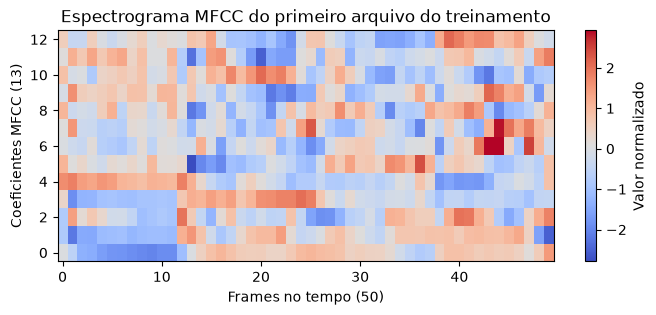

In [5]:
sinal_treino = padronizar_audio_1s(arquivos_treino[0])                                 
mfcc = extrair_mfcc(sinal_treino)                                                      
                                                                                        
print("Shape do MFCC:", mfcc.shape) # Esperado: torch.Size([13, 50])                   
                                                                                        
plt.figure(figsize=(8, 3))                                                             
plt.imshow(mfcc.numpy(), aspect="auto", origin="lower", cmap="coolwarm")               
plt.colorbar(label="Valor normalizado")                                                
plt.xlabel("Frames no tempo (50)")                                                     
plt.ylabel("Coeficientes MFCC (13)")                                                   
plt.title("Espectrograma MFCC do primeiro arquivo do treinamento")                                                        
plt.show()   



### 1.6 Dataset PyTorch, Divisão dos Conjuntos e DataLoaders

Para alimentar a rede neural no PyTorch de forma eficiente, criou-se a classe `KWSDataset`, que pré-computa e armazena na memória RAM os tensores MFCC `(13, 50)` e os respectivos rótulos numéricos (`0` a `5`) de todos os áudios. Em seguida, o conjunto de treino (1.050 amostras) foi dividido em 80% para treinamento (840 amostras) e 20% para validação (210 amostras), mantendo as 252 amostras de teste isoladas. Por fim, os dados foram organizados em `DataLoader`s com lotes (*batches*) de tamanho 32, embaralhando apenas o conjunto de treinamento a cada época.

In [6]:
class KWSDataset(Dataset): 
        def __init__(self, lista_arquivos, class_to_idx):
            features_lista = [] 
            labels_lista = [] 
  
            for caminho in lista_arquivos:
                # 1. Padroniza para 16.000 amostras e extrai MFCC -> shape (13, 50)        
                sinal = padronizar_audio_1s(caminho)
                mfcc = extrair_mfcc(sinal)
                
                # 2. Extrai o nome da classe pelo prefixo do arquivo e converte para 0..5  
                nome_classe = caminho.name.split(".")[0]
                label = class_to_idx[nome_classe]
                
                features_lista.append(mfcc)
                labels_lista.append(label)
  
            # Empilha tudo em dois tensores na RAM: X = (N, 13, 50) e y = (N,)
            self.X = torch.stack(features_lista)
            self.y = torch.tensor(labels_lista, dtype=torch.long)
  
        def __len__(self):
            return len(self.y)
  
        def __getitem__(self, idx):
            return self.X[idx], self.y[idx]
        
# Constrói os datasets pré-computados                  
full_train_dataset = KWSDataset(arquivos_treino, CLASS_TO_IDX)                         
test_dataset       = KWSDataset(arquivos_teste, CLASS_TO_IDX)

# Divide os 1.050 de treino em 80% treino (840) e 20% validação (210)
generator = torch.Generator().manual_seed(42)
train_size = int(0.8 * len(full_train_dataset))
val_size   = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size],  
generator=generator)

# Cria os DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=0)  
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=0)  
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=0)  

x_lote, y_lote = next(iter(train_loader))
print(f"Amostras -> Treino: {len(train_dataset)} | Validação: {len(val_dataset)} | Teste: {len(test_dataset)}")
print("Shape do lote de entrada (Batch, Canais, Frames):", x_lote.shape)
print("Shape dos rótulos:", y_lote.shape, "| Tipo:", y_lote.dtype)


Amostras -> Treino: 840 | Validação: 210 | Teste: 252
Shape do lote de entrada (Batch, Canais, Frames): torch.Size([32, 13, 50])
Shape dos rótulos: torch.Size([32]) | Tipo: torch.int64


### 1.7 Análise Estatística da Distribuição MFCC

Realizou-se uma análise estatística da distribuição global dos coeficientes MFCC normalizados no conjunto de treinamento. Os resultados confirmaram média zero (`-0.000`) e desvio padrão unitário (`0.999`), evidenciando a atuação da normalização CMVN, além de valores extremos assimétricos (`-6.362` a `+5.051`).

Mínimo: -6.362 | Máximo: 5.051
Média:  -0.000 | Desvio Padrão: 0.999


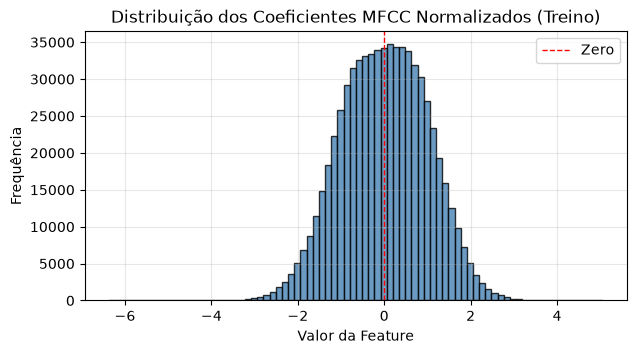

In [7]:
valores_mfcc = full_train_dataset.X.flatten().numpy()

print(f"Mínimo: {valores_mfcc.min():.3f} | Máximo: {valores_mfcc.max():.3f}")          
print(f"Média:  {valores_mfcc.mean():.3f} | Desvio Padrão: {valores_mfcc.std():.3f}")  

plt.figure(figsize=(7, 3.5)) 
plt.hist(valores_mfcc, bins=80, color="steelblue", edgecolor="black", alpha=0.8)
plt.axvline(0, color="red", linestyle="--", linewidth=1, label="Zero")
plt.title("Distribuição dos Coeficientes MFCC Normalizados (Treino)")
plt.xlabel("Valor da Feature")
plt.ylabel("Frequência")
plt.legend()
plt.grid(alpha=0.3)
plt.show() 


### 1.8 Arquitetura da Rede Neural (`KWS_CNN`)

Realizou-se a configuração da rede neural para o treinamento. Para isso, foi construída a arquitetura da Rede Neural Convolucional de 1 dimensão (1D-CNN), reproduzindo a arquitetura adotada no Edge Impulse para entradas no formato `(Batch, 13, 50)` e totalizando `1.974` parâmetros treináveis (Carlos, 2025):

- **Bloco Convolucional 1:**
  - `Conv1d(13 -> 8 filtros, kernel_size=3, padding=1)` para extrair padrões temporais iniciais mantendo os 50 quadros;
  - Ativação `ReLU`;
  - `MaxPool1d(kernel_size=2, ceil_mode=True)` reduzindo a dimensão temporal de `50` para `25` quadros;
  - `Dropout(0.25)` para regularização.
- **Bloco Convolucional 2:**
  - `Conv1d(8 -> 16 filtros, kernel_size=3, padding=1)` mantendo os 25 quadros;
  - Ativação `ReLU`;
  - `MaxPool1d(kernel_size=2, ceil_mode=True)` reduzindo de `25` para `13` quadros (o `ceil_mode=True` garante a equivalência com o *padding* `'same'` do Edge Impulse);
  - `Dropout(0.25)`.
- **Classificador:**
  - `Flatten` transformando o tensor `(16, 13)` em um vetor de `208` características;
  - Camada linear `Linear(208, 6)` gerando os 6 *logits* de saída correspondentes às classes.

In [8]:
class KWS_CNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__() # Inicializa a classe nn.Module          
                                                                                        
        # Bloco 1: 13 canais -> 8 filtros
        self.conv1 = nn.Conv1d(in_channels=13, out_channels=8, kernel_size=3,          
        padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, ceil_mode=True)
        self.drop1 = nn.Dropout(0.25)

        # Bloco 2: 8 canais -> 16 filtros
        self.conv2 = nn.Conv1d(in_channels=8, out_channels=16, kernel_size=3,          
        padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, ceil_mode=True)
        self.drop2 = nn.Dropout(0.25)

        # Classificador: 16 filtros * 13 frames = 208 entradas -> 6 classes            
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(16 * 13, num_classes)

    def forward(self, x):
        # Passagem pelo Bloco 1
        x = self.drop1(self.pool1(self.relu1(self.conv1(x))))
        # Passagem pelo Bloco 2
        x = self.drop2(self.pool2(self.relu2(self.conv2(x))))
        # Classificação
        x = self.flatten(x)
        x = self.fc(x)
        return x

# Cria o modelo e envia para o device (CPU)
modelo_fp32 = KWS_CNN(num_classes=len(CLASSES)).to(device)

# Conta quantos parâmetros (pesos + vieses) a rede tem no total
total_params = sum(p.numel() for p in modelo_fp32.parameters())
print(modelo_fp32)
print(f"\nTotal de parâmetros treináveis: {total_params}")

# Teste de passagem (Forward Pass) com 1 lote sem calcular gradientes
modelo_fp32.eval()
with torch.no_grad():
    saida_teste = modelo_fp32(x_lote.to(device))

print("Shape da saída da rede:", saida_teste.shape) # Esperado: torch.Size([32, 6]) 


KWS_CNN(
  (conv1): Conv1d(13, 8, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu1): ReLU()
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
  (drop1): Dropout(p=0.25, inplace=False)
  (conv2): Conv1d(8, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu2): ReLU()
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
  (drop2): Dropout(p=0.25, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=208, out_features=6, bias=True)
)

Total de parâmetros treináveis: 1974
Shape da saída da rede: torch.Size([32, 6])


## 2. Treinamento do Baseline (FP32)

### 2.1 Protocolo e Execução do Treinamento

Realizou-se o treinamento do modelo `KWS_CNN` em precisão total (`FP32`) por `300` épocas, mantendo os mesmos hiperparâmetros configurados no Edge Impulse (Carlos, 2025):

- **Função de perda e otimizador:** `CrossEntropyLoss` com otimizador `Adam` (`lr = 0.005`) e *batches* de tamanho `32`;
- **Protocolo de validação (*holdout*):** `840` amostras para treino (`80%`) e `210` para validação (`20%`);
- **Model Checkpoint:** os pesos com maior acurácia de validação foram salvos em     `baseline_fp32.pth` (pico de `93.33%`, enquanto a validação ao final das épocas oscilou entre `88.1%` e `90.5%`, alinhada aos `89.0%` observados em Carlos, 2025).

In [9]:
# Fixa a semente para o treinamento ser reprodutível e cria um modelo novo do zero     
torch.manual_seed(42)                                                                  
modelo_fp32 = KWS_CNN(num_classes=len(CLASSES)).to(device)                             
                                                                                        
criterion = nn.CrossEntropyLoss()                                                      
optimizer = torch.optim.Adam(modelo_fp32.parameters(), lr=0.005)                       
                                                                                        
num_epochs = 300                                                                       
best_val_acc = 0.0                                                                     
                                                                                        
# Dicionário para guardar o histórico e plotar gráficos depois                         
historico = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}         
                                                                                        
for epoch in range(1, num_epochs + 1):                                                 
    # --- FASE DE TREINO (liga o Dropout) ---                                          
    modelo_fp32.train()                                                                
    train_loss_acum, train_corretos = 0.0, 0                                           
                                                                                        
    for x_batch, y_batch in train_loader:                                              
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)                      
                                                                                        
        optimizer.zero_grad()                  # 1. Zera gradientes                    
        outputs = modelo_fp32(x_batch)         # 2. Forward                            
        loss = criterion(outputs, y_batch)     # 3. Calcula erro                       
        loss.backward()                        # 4. Calcula derivadas                  
        optimizer.step()                       # 5. Atualiza pesos                     
                                                                                        
        train_loss_acum += loss.item() * x_batch.size(0)                               
        preds = outputs.argmax(dim=1)          # Pega a classe de maior pontuação (0..5)                                                                         
        train_corretos += (preds == y_batch).sum().item()                              
                                                                                        
    train_loss = train_loss_acum / len(train_loader.dataset)                           
    train_acc  = train_corretos / len(train_loader.dataset)                            
                                                                                        
    # --- FASE DE VALIDAÇÃO (desliga o Dropout e não calcula gradientes) ---           
    modelo_fp32.eval()                                                                 
    val_loss_acum, val_corretos = 0.0, 0                                               
                                                                                        
    with torch.no_grad():                                                              
        for x_batch, y_batch in val_loader:                                            
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)                  
            outputs = modelo_fp32(x_batch)                                             
            loss = criterion(outputs, y_batch)                                         
                                                                                        
            val_loss_acum += loss.item() * x_batch.size(0)                             
            preds = outputs.argmax(dim=1)                                              
            val_corretos += (preds == y_batch).sum().item()                            
                                                                                        
    val_loss = val_loss_acum / len(val_loader.dataset)                                 
    val_acc  = val_corretos / len(val_loader.dataset)                                  
                                                                                        
    historico["train_loss"].append(train_loss)                                         
    historico["val_loss"].append(val_loss)                                             
    historico["train_acc"].append(train_acc)                                           
    historico["val_acc"].append(val_acc)                                               
                                                                                        
    # Salva os pesos sempre que atingir uma nova melhor acurácia de validação          
    if val_acc > best_val_acc:                                                         
        best_val_acc = val_acc                                                         
        torch.save(modelo_fp32.state_dict(), "baseline_fp32.pth")                      
                                                                                        
    # Imprime a cada 30 épocas                     
    if epoch == 1 or epoch % 30 == 0:                                                  
        print(f"Época {epoch:3d}/{num_epochs} | "                                      
                f"Treino Loss: {train_loss:.4f}, Acc: {train_acc*100:.1f}% | "           
                f"Val Loss: {val_loss:.4f}, Acc: {val_acc*100:.1f}%")                    

print(f"\nMelhor acurácia de validação salva em 'baseline_fp32.pth': {best_val_acc*100:.2f}%")

Época   1/300 | Treino Loss: 1.3197, Acc: 50.6% | Val Loss: 0.7788, Acc: 74.3%
Época  30/300 | Treino Loss: 0.1964, Acc: 93.3% | Val Loss: 0.3116, Acc: 90.5%
Época  60/300 | Treino Loss: 0.1244, Acc: 96.1% | Val Loss: 0.3415, Acc: 90.5%
Época  90/300 | Treino Loss: 0.1080, Acc: 96.1% | Val Loss: 0.3158, Acc: 88.6%
Época 120/300 | Treino Loss: 0.1087, Acc: 96.4% | Val Loss: 0.3052, Acc: 90.5%
Época 150/300 | Treino Loss: 0.0860, Acc: 96.7% | Val Loss: 0.2673, Acc: 90.0%
Época 180/300 | Treino Loss: 0.0924, Acc: 96.4% | Val Loss: 0.3320, Acc: 90.0%
Época 210/300 | Treino Loss: 0.0949, Acc: 97.4% | Val Loss: 0.2675, Acc: 89.0%
Época 240/300 | Treino Loss: 0.0519, Acc: 98.2% | Val Loss: 0.1731, Acc: 93.3%
Época 270/300 | Treino Loss: 0.0762, Acc: 96.9% | Val Loss: 0.2422, Acc: 91.9%
Época 300/300 | Treino Loss: 0.0870, Acc: 97.4% | Val Loss: 0.2667, Acc: 88.1%

Melhor acurácia de validação salva em 'baseline_fp32.pth': 93.33%


### 2.2 Curvas de Convergência (Loss e Acurácia)

Plotou-se a evolução do *Loss* e da *Acurácia* ao longo das `300` épocas a partir do dicionário `historico` para verificar a convergência do modelo, identificar o ponto ótimo salvo em `baseline_fp32.pth` e inspecionar visualmente a ocorrência de *overfitting*.

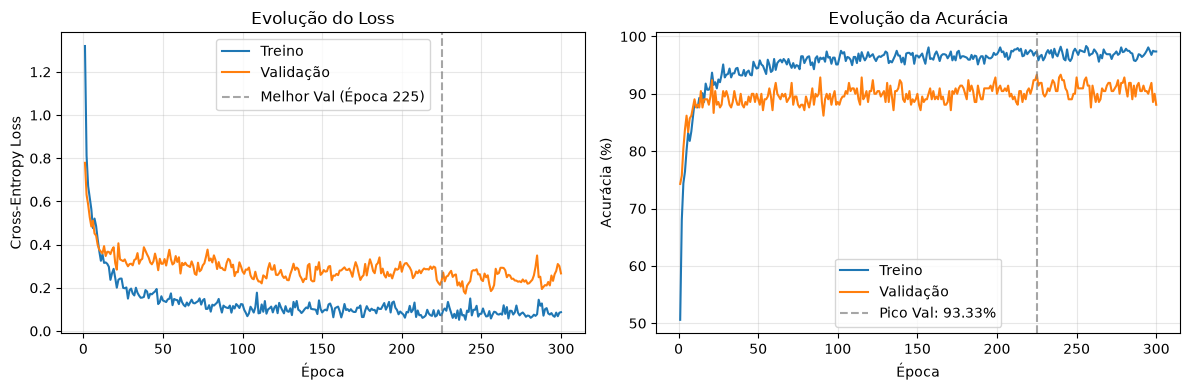

In [10]:
epocas = range(1, len(historico["train_loss"]) + 1)
melhor_epoca = int(np.argmax(historico["val_acc"])) + 1
melhor_val_acc = historico["val_acc"][melhor_epoca - 1] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: Loss                                                                      
axes[0].plot(epocas, historico["train_loss"], label="Treino")
axes[0].plot(epocas, historico["val_loss"], label="Validação")
axes[0].axvline(melhor_epoca, color="gray", linestyle="--", alpha=0.7,
                label=f"Melhor Val (Época {melhor_epoca})")
axes[0].set_title("Evolução do Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Acurácia
axes[1].plot(epocas, [a * 100 for a in historico["train_acc"]], label="Treino")        
axes[1].plot(epocas, [a * 100 for a in historico["val_acc"]], label="Validação")       
axes[1].axvline(melhor_epoca, color="gray", linestyle="--", alpha=0.7,
                label=f"Pico Val: {melhor_val_acc:.2f}%")
axes[1].set_title("Evolução da Acurácia")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.3 Função de Avaliação e Resultados do Baseline FP32

Implementou-se a função reutilizável `avaliar_modelo` — que será reaproveitada nas etapas de **PTQ** e **QAT** — para calcular as mesmas métricas do Edge Impulse (`Accuracy`, `Loss`, `ROC AUC`, `Precision`, `Recall`, `F1-Score` ponderado e por classe) e plotar a Matriz de Confusão em porcentagem por linha:

- **Validação (`210` amostras):** atingiu `93.33%` de acurácia, *Loss* `0.2318`, *ROC AUC* `0.9948` e *F1 ponderado* `0.9331`;
- **Teste isolado (`252` amostras inéditas):** atingiu `91.27%` de acurácia (`230/252`), *ROC AUC* `0.9893` e *F1 ponderado* `0.9131`, empatando tecnicamente com a referência `Unoptimized (float32)` do Edge Impulse (`91.83%` no teste; Carlos, 2025) e confirmando boa capacidade de generalização.

=== Baseline FP32 (Validação) (210 amostras) ===
Accuracy                 : 93.33%
Loss                     : 0.2318
Area under ROC Curve     : 0.9948
Weighted avg Precision   : 0.9338
Weighted avg Recall      : 0.9333
Weighted avg F1 score    : 0.9331

F1 Score por classe:
  - desconhecido : 0.8750 (n=32)
  - dois         : 0.9639 (n=41)
  - ruido        : 0.9394 (n=33)
  - tres         : 0.9091 (n=38)
  - um           : 0.9254 (n=35)
  - zero         : 0.9841 (n=31)


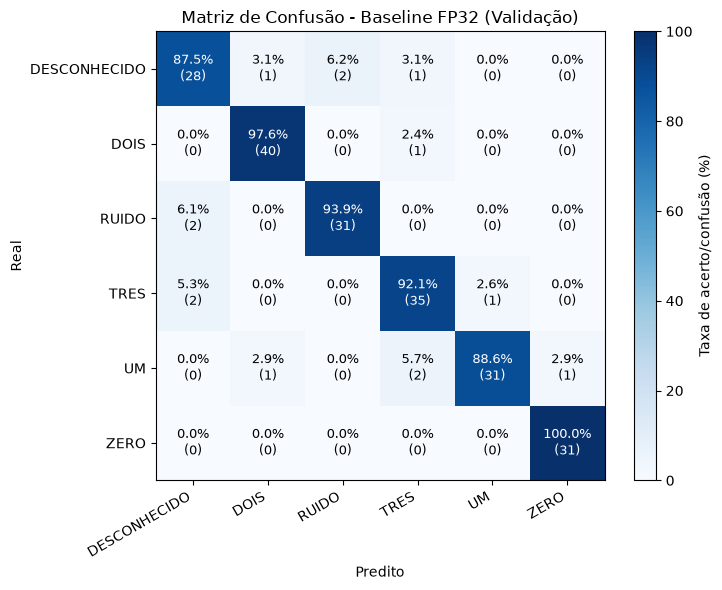

=== Baseline FP32 (Teste) (252 amostras) ===
Accuracy                 : 91.27%
Loss                     : 0.4191
Area under ROC Curve     : 0.9893
Weighted avg Precision   : 0.9145
Weighted avg Recall      : 0.9127
Weighted avg F1 score    : 0.9131

F1 Score por classe:
  - desconhecido : 0.8333 (n=42)
  - dois         : 0.9176 (n=43)
  - ruido        : 0.8989 (n=43)
  - tres         : 0.9398 (n=42)
  - um           : 0.9268 (n=40)
  - zero         : 0.9630 (n=42)


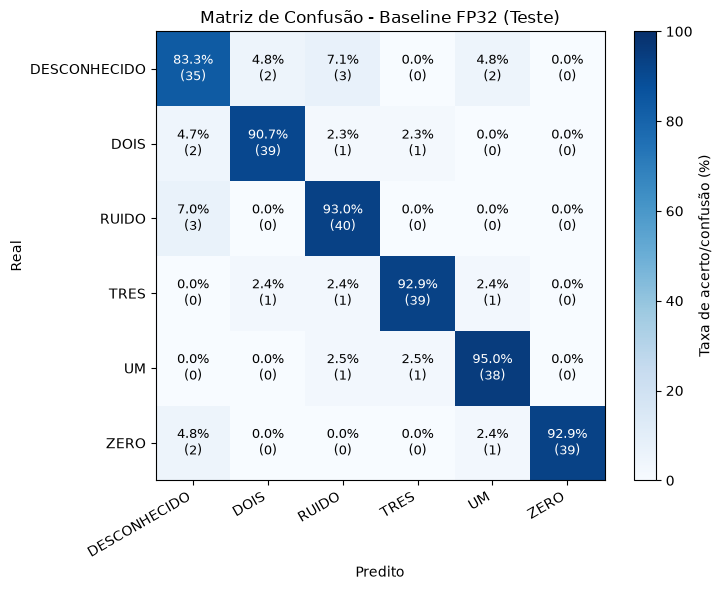

In [11]:
def avaliar_modelo(modelo, loader, classes, criterion, device, titulo="Avaliação", plotar_matriz=True):
    modelo.eval()  # Desliga Dropout para inferência determinística
    loss_acum = 0.0
    todas_probs = []
    todos_preds = []
    todos_alvos = [] 

    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            logits = modelo(x_batch)
            loss = criterion(logits, y_batch)

            loss_acum += loss.item() * x_batch.size(0) 
            probs = F.softmax(logits, dim=1)       # Converte logits em probabilidades (0..1)
            preds = logits.argmax(dim=1)           # Classe prevista

            todas_probs.append(probs.cpu().numpy()) 
            todos_preds.append(preds.cpu().numpy())
            todos_alvos.append(y_batch.cpu().numpy()) 

    y_true = np.concatenate(todos_alvos)
    y_pred = np.concatenate(todos_preds)
    # float64 + renormalização evita erro de arredondamento do float32 no roc_auc_score
    y_probs = np.vstack(todas_probs).astype(np.float64) 
    y_probs = y_probs / y_probs.sum(axis=1, keepdims=True) 

    # Métricas globais (iguais às da tabela do Edge Impulse)                           
    loss_medio = loss_acum / len(loader.dataset)
    acc = accuracy_score(y_true, y_pred)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    _, _, f1_por_classe, suporte = precision_recall_fscore_support(
        y_true, y_pred, labels=range(len(classes)), average=None, zero_division=0      
    )
    auc = roc_auc_score(y_true, y_probs, multi_class="ovr", average="weighted")        

    print(f"=== {titulo} ({len(y_true)} amostras) ===")
    print(f"Accuracy                 : {acc * 100:.2f}%")
    print(f"Loss                     : {loss_medio:.4f}")
    print(f"Area under ROC Curve     : {auc:.4f}")
    print(f"Weighted avg Precision   : {prec_w:.4f}")
    print(f"Weighted avg Recall      : {rec_w:.4f}")
    print(f"Weighted avg F1 score    : {f1_w:.4f}\n")

    print("F1 Score por classe:")
    for nome, f1_c, n_c in zip(classes, f1_por_classe, suporte):
        print(f"  - {nome:<13}: {f1_c:.4f} (n={n_c})")

    # Matriz de Confusão (% por linha + contagem absoluta)
    cm = confusion_matrix(y_true, y_pred, labels=range(len(classes)))
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100.0

    if plotar_matriz:
        fig, ax = plt.subplots(figsize=(7.5, 6))
        im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
        plt.colorbar(im, ax=ax, label="Taxa de acerto/confusão (%)")

        ax.set_xticks(range(len(classes)))
        ax.set_yticks(range(len(classes)))
        ax.set_xticklabels([c.upper() for c in classes], rotation=30, ha="right")          
        ax.set_yticklabels([c.upper() for c in classes])
        ax.set_xlabel("Predito")
        ax.set_ylabel("Real")
        ax.set_title(f"Matriz de Confusão - {titulo}") 

        for i in range(len(classes)): 
            for j in range(len(classes)): 
                cor = "white" if cm_pct[i, j] > 55 else "black" 
                ax.text(
                    j, i, f"{cm_pct[i, j]:.1f}%\n({cm[i, j]})",
                    ha="center", va="center", color=cor, fontsize=9
                )

        plt.tight_layout()
        plt.show() 

    return {
        "acc": acc,
        "loss": loss_medio, 
        "auc": auc,
        "precision_w": prec_w,
        "recall_w": rec_w,
        "f1_w": f1_w,
        "f1_por_classe": f1_por_classe,
        "cm": cm,
    }


# Carrega o melhor checkpoint salvo durante o treino
modelo_fp32_best = KWS_CNN(num_classes=len(CLASSES)).to(device)
modelo_fp32_best.load_state_dict(
    torch.load("baseline_fp32.pth", map_location=device, weights_only=True) 
)

# 1) Validação (210 amostras) -> comparação direta com o print do Edge Impulse
metricas_fp32_val = avaliar_modelo( 
    modelo_fp32_best, val_loader, CLASSES, criterion, device,
    titulo="Baseline FP32 (Validação)"
)

# 2) Teste isolado (252 amostras nunca vistas) -> referência oficial do projeto!
metricas_fp32_test = avaliar_modelo(
    modelo_fp32_best, test_loader, CLASSES, criterion, device,
    titulo="Baseline FP32 (Teste)"
)

## 3. Quantização

### 3.1 Funções Auxiliares Compartilhadas (Fake Quantization e Calibração)

Implementou-se o conjunto de funções auxiliares compartilhadas para a simulação de quantização linear uniforme em ponto fixo (representação *fake quantization*, compatível com hardware inteiro — Lin et al., 2023):

- **`calcular_limites_inteiros`:** define o intervalo inteiro $[q_{\min}, q_{\max}]$ com $2^b$ níveis para tensores com sinal ($[-2^{b-1},\, 2^{b-1}-1]$ para pesos e entrada MFCC) e sem sinal ($[0,\, 2^b-1]$ para ativações pós-ReLU), mantendo compatibilidade direta entre PTQ, LSQ e LSQ+.
- **`fake_quantize_uniforme`:** executa o mapeamento quantização-desquantização ($Q/DQ$), projetando valores contínuos para a grade discreta de tamanho de passo `scale` seguida de *clipping* e retorno ao domínio de ponto flutuante, com *Straight-Through Estimator* (STE; Lin et al., 2023) integrado para suportar tanto **PTQ** quanto **QAT**.
- **`calibrar_escala`:** estima o parâmetro `scale` por dois critérios: **Min-Max** (cobrindo toda a amplitude $[x_{\min}, x_{\max}]$) e **MSE** (busca em grade de um fator $\alpha \in [0{,}2;\, 1{,}0]$ para minimizar o erro quadrático médio entre o tensor original e o quantizado, reduzindo o impacto de *outliers* — Zhao et al., 2021; Pereira et al., 2023).

In [12]:
def calcular_limites_inteiros(num_bits, signed=True):
    """Retorna (q_min, q_max) padrão para num_bits (alinhado ao LSQ)."""
    if signed:
        q_min = -(2 ** (num_bits - 1))
        q_max = (2 ** (num_bits - 1)) - 1
    else:
        q_min = 0
        q_max = (2 ** num_bits) - 1 
    return q_min, q_max 


def fake_quantize_uniforme(x, scale, zero_point, q_min, q_max):
    """Simula quantização uniforme com STE (compatível com PTQ e QAT)."""
    scale = torch.clamp(torch.as_tensor(scale, dtype=x.dtype, device=x.device), min=1e-8)
    x_scaled = torch.clamp(x / scale + zero_point, q_min, q_max)
    x_q = (torch.round(x_scaled) - x_scaled).detach() + x_scaled
    return (x_q - zero_point) * scale


def calibrar_escala(tensor, num_bits, signed=True, metodo="minmax", num_passos=80): 
    """Calcula a escala ótima pelo método Min-Max ou minimizando o MSE."""
    q_min, q_max = calcular_limites_inteiros(num_bits, signed=signed)
    if signed:
        max_ref = tensor.abs().max()
        q_ref = max(abs(q_min), abs(q_max))
    else:
        max_ref = tensor.max()
        q_ref = q_max

    scale_minmax = torch.clamp(max_ref / q_ref, min=1e-8)
    if metodo == "minmax":
        return scale_minmax 

    melhor_scale = scale_minmax
    menor_mse = float("inf") 
    for alpha in torch.linspace(0.2, 1.0, num_passos, device=tensor.device):
        s_cand = scale_minmax * alpha
        q_cand = fake_quantize_uniforme(tensor, s_cand, 0, q_min, q_max)
        mse = torch.mean((tensor - q_cand) ** 2).item()
        if mse < menor_mse:
            menor_mse = mse 
            melhor_scale = s_cand
    return melhor_scale

### 3.2 PTQ — Post-Training Quantization (Min-Max vs. MSE)

Aplicou-se a quantização pós-treinamento sobre o modelo *baseline* `FP32` já treinado (`baseline_fp32.pth`), sem reajuste dos pesos — emulando em `W8A8` a estratégia `PTQ INT8` padrão adotada no Edge Impulse (Carlos, 2025) e estendendo a análise para `W4A4` e `W2A2`. Para evitar vazamento de dados (*data   leakage*), todas as escalas de quantização da entrada (`in`), das ativações (`a1`, `a2`) e dos pesos (`w1`, `w2`, `wfc`) foram calibradas exclusivamente sobre o conjunto de treino (`840` amostras), avaliando-se o desempenho final no conjunto de teste isolado (`252` amostras) nas precisões **W8A8**, **W4A4** e **W2A2**, comparando os métodos de calibração **Min-Max** e **MSE** (Pereira et al., 2023; Zhao et al., 2021; Ravaglia et al., 2021).

=== PTQ W8A8 (MINMAX) (252 amostras) ===
Accuracy                 : 91.27%
Loss                     : 0.4183
Area under ROC Curve     : 0.9894
Weighted avg Precision   : 0.9138
Weighted avg Recall      : 0.9127
Weighted avg F1 score    : 0.9128

F1 Score por classe:
  - desconhecido : 0.8333 (n=42)
  - dois         : 0.9176 (n=43)
  - ruido        : 0.9091 (n=43)
  - tres         : 0.9268 (n=42)
  - um           : 0.9398 (n=40)
  - zero         : 0.9512 (n=42)


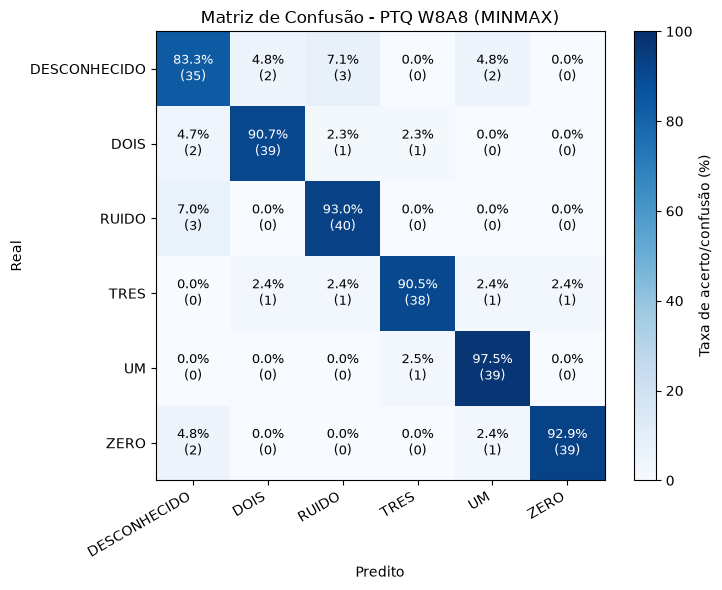

=== PTQ W4A4 (MINMAX) (252 amostras) ===
Accuracy                 : 86.90%
Loss                     : 0.6890
Area under ROC Curve     : 0.9811
Weighted avg Precision   : 0.8753
Weighted avg Recall      : 0.8690
Weighted avg F1 score    : 0.8693

F1 Score por classe:
  - desconhecido : 0.7955 (n=42)
  - dois         : 0.8810 (n=43)
  - ruido        : 0.8889 (n=43)
  - tres         : 0.8533 (n=42)
  - um           : 0.8675 (n=40)
  - zero         : 0.9286 (n=42)


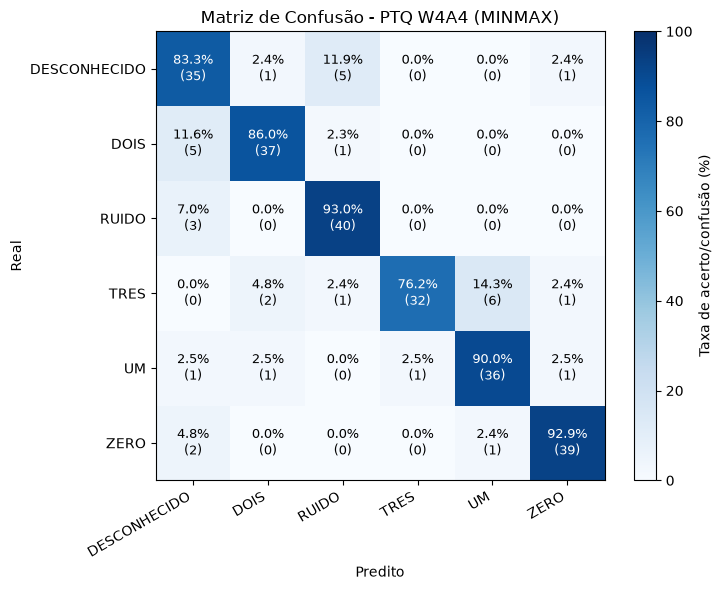

=== PTQ W2A2 (MINMAX) (252 amostras) ===
Accuracy                 : 19.05%
Loss                     : 11.5572
Area under ROC Curve     : 0.6021
Weighted avg Precision   : 0.3083
Weighted avg Recall      : 0.1905
Weighted avg F1 score    : 0.1343

F1 Score por classe:
  - desconhecido : 0.2383 (n=42)
  - dois         : 0.0000 (n=43)
  - ruido        : 0.3393 (n=43)
  - tres         : 0.0816 (n=42)
  - um           : 0.0968 (n=40)
  - zero         : 0.0465 (n=42)


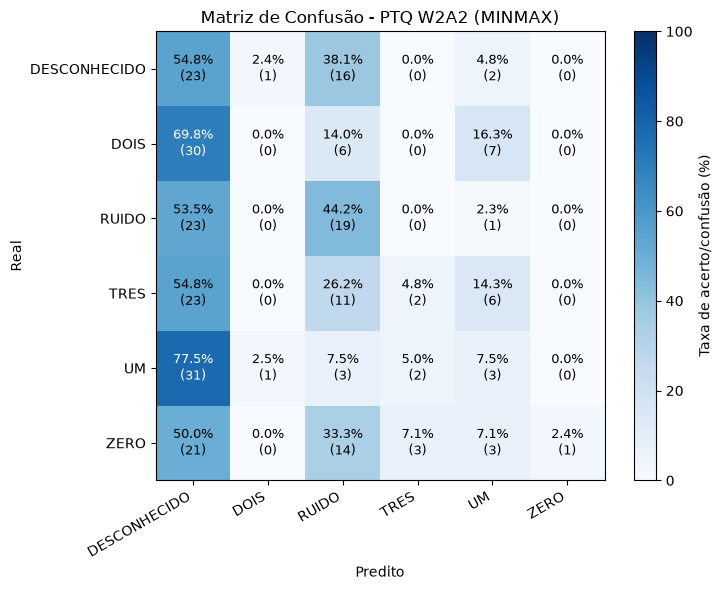

=== PTQ W8A8 (MSE) (252 amostras) ===
Accuracy                 : 90.87%
Loss                     : 0.4162
Area under ROC Curve     : 0.9896
Weighted avg Precision   : 0.9102
Weighted avg Recall      : 0.9087
Weighted avg F1 score    : 0.9090

F1 Score por classe:
  - desconhecido : 0.8333 (n=42)
  - dois         : 0.9176 (n=43)
  - ruido        : 0.8989 (n=43)
  - tres         : 0.9268 (n=42)
  - um           : 0.9268 (n=40)
  - zero         : 0.9512 (n=42)


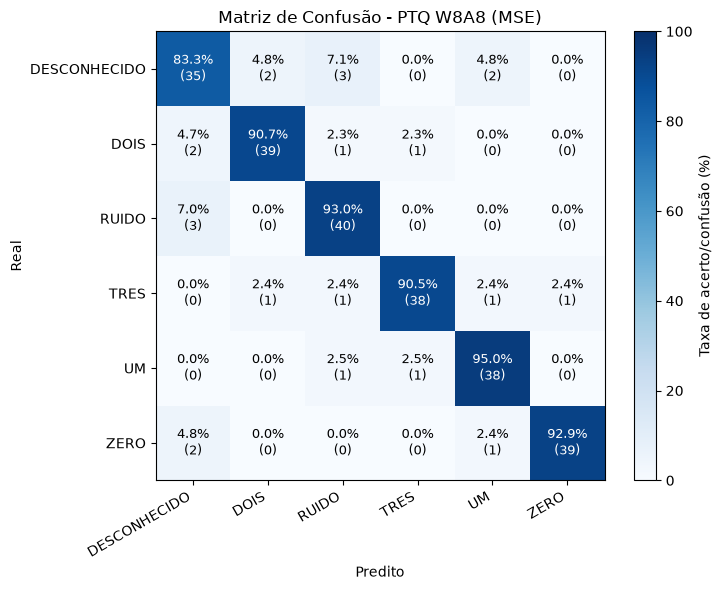

=== PTQ W4A4 (MSE) (252 amostras) ===
Accuracy                 : 89.29%
Loss                     : 0.4882
Area under ROC Curve     : 0.9868
Weighted avg Precision   : 0.8965
Weighted avg Recall      : 0.8929
Weighted avg F1 score    : 0.8929

F1 Score por classe:
  - desconhecido : 0.7901 (n=42)
  - dois         : 0.9286 (n=43)
  - ruido        : 0.8723 (n=43)
  - tres         : 0.9250 (n=42)
  - um           : 0.9136 (n=40)
  - zero         : 0.9286 (n=42)


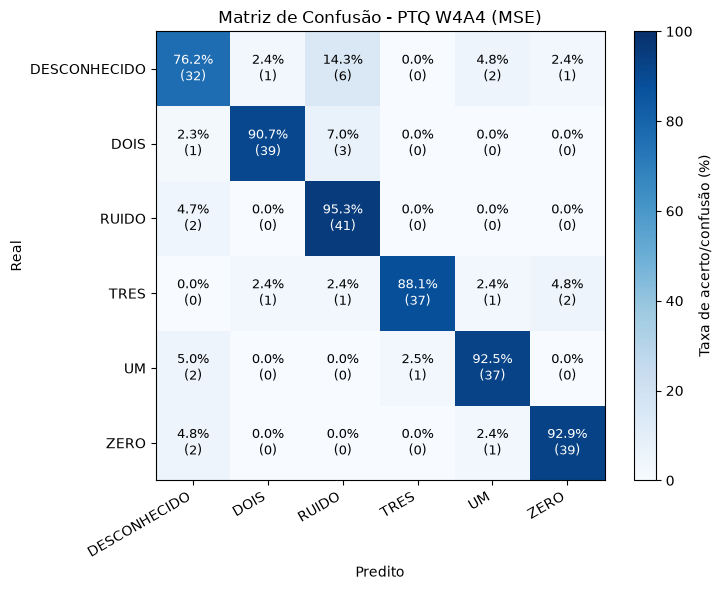

=== PTQ W2A2 (MSE) (252 amostras) ===
Accuracy                 : 79.37%
Loss                     : 0.8546
Area under ROC Curve     : 0.9577
Weighted avg Precision   : 0.8028
Weighted avg Recall      : 0.7937
Weighted avg F1 score    : 0.7955

F1 Score por classe:
  - desconhecido : 0.7273 (n=42)
  - dois         : 0.7857 (n=43)
  - ruido        : 0.7660 (n=43)
  - tres         : 0.8205 (n=42)
  - um           : 0.8148 (n=40)
  - zero         : 0.8608 (n=42)


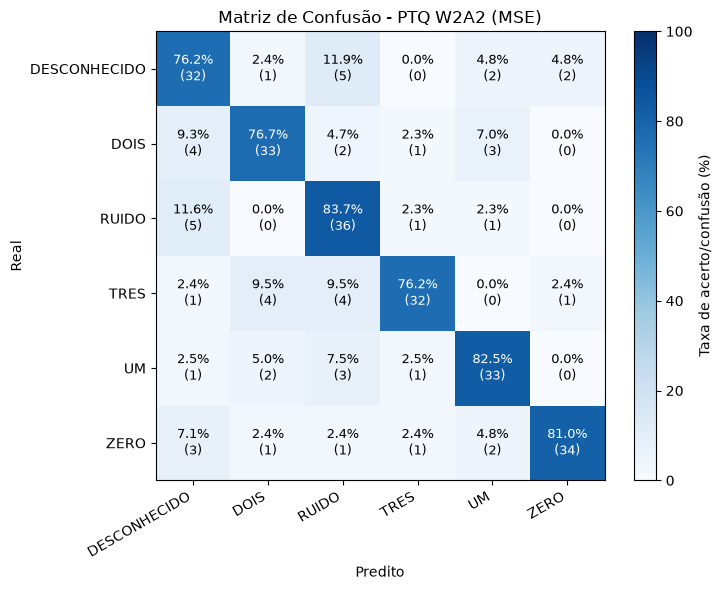


Modelo                   |  Acc (%) |     Loss |     AUC |    F1-W
------------------------------------------------------------------------
Baseline FP32            |   91.27% |   0.4191 |  0.9893 |  0.9131
PTQ W8A8 (MINMAX)        |   91.27% |   0.4183 |  0.9894 |  0.9128
PTQ W4A4 (MINMAX)        |   86.90% |   0.6890 |  0.9811 |  0.8693
PTQ W2A2 (MINMAX)        |   19.05% |  11.5572 |  0.6021 |  0.1343
PTQ W8A8 (MSE)           |   90.87% |   0.4162 |  0.9896 |  0.9090
PTQ W4A4 (MSE)           |   89.29% |   0.4882 |  0.9868 |  0.8929
PTQ W2A2 (MSE)           |   79.37% |   0.8546 |  0.9577 |  0.7955


In [13]:
def coletar_ativacoes_calibracao(modelo, loader, device): 
    """Passa o conjunto de treino para capturar entrada MFCC e ativações pós-ReLU."""
    modelo.eval()
    entradas, act1_lista, act2_lista = [], [], [] 
    with torch.no_grad(): 
        for x_batch, _ in loader: 
            x_batch = x_batch.to(device)
            entradas.append(x_batch)
            a1 = modelo.relu1(modelo.conv1(x_batch)) 
            act1_lista.append(a1)
            h1 = modelo.pool1(a1)
            a2 = modelo.relu2(modelo.conv2(h1))
            act2_lista.append(a2)
    return {
        "in": torch.cat(entradas, dim=0), 
        "a1": torch.cat(act1_lista, dim=0),
        "a2": torch.cat(act2_lista, dim=0),
    }


class KWS_CNN_PTQ(nn.Module):
    """Envolve o modelo FP32 treinado aplicando Fake Quantization PTQ em pesos e      
    ativações."""
    def __init__(self, modelo_fp32, escalas, num_bits):
        super().__init__()
        self.base = copy.deepcopy(modelo_fp32).eval() 
        self.escalas = escalas

        q_min_w, q_max_w = calcular_limites_inteiros(num_bits, signed=True)
        self.w1_q = fake_quantize_uniforme(self.base.conv1.weight.data, escalas["w1"],
        0, q_min_w, q_max_w) 
        self.w2_q = fake_quantize_uniforme(self.base.conv2.weight.data, escalas["w2"],
        0, q_min_w, q_max_w) 
        self.wfc_q = fake_quantize_uniforme(self.base.fc.weight.data, escalas["wfc"],
        0, q_min_w, q_max_w)

        self.q_min_in, self.q_max_in = calcular_limites_inteiros(num_bits, signed=True)
        self.q_min_act, self.q_max_act = calcular_limites_inteiros(num_bits,
        signed=False)

    def forward(self, x):
        # 1. Entrada MFCC (signed) 
        x = fake_quantize_uniforme(x, self.escalas["in"], 0, self.q_min_in,     
        self.q_max_in)

        # 2. Bloco 1 (pesos conv1 -> ReLU -> ativações unsigned -> MaxPool)
        x = F.conv1d(x, self.w1_q, self.base.conv1.bias,
                        stride=self.base.conv1.stride, padding=self.base.conv1.padding)
        x = self.base.relu1(x)
        x = fake_quantize_uniforme(x, self.escalas["a1"], 0, self.q_min_act,
        self.q_max_act) 
        x = self.base.pool1(x)

        # 3. Bloco 2
        x = F.conv1d(x, self.w2_q, self.base.conv2.bias,
                        stride=self.base.conv2.stride, padding=self.base.conv2.padding)
        x = self.base.relu2(x)
        x = fake_quantize_uniforme(x, self.escalas["a2"], 0, self.q_min_act,      
        self.q_max_act)
        x = self.base.pool2(x)

        # 4. Classificador
        x = self.base.flatten(x)
        x = F.linear(x, self.wfc_q, self.base.fc.bias) 
        return x


# 1. Calibra uma única vez sobre os 840 áudios de treino (sem tocar no teste!)
ativacoes_calib = coletar_ativacoes_calibracao(modelo_fp32_best, train_loader, device)
                                                                                        
# 2. Executa PTQ para W8A8, W4A4 e W2A2 nos dois métodos de calibração                 
resultados_ptq = {}                                                                    
                                                                                        
for metodo in ["minmax", "mse"]:
    for bits in [8, 4, 2]:
        escalas = {
            "in":  calibrar_escala(ativacoes_calib["in"], bits, signed=True, metodo=metodo),
            "a1":  calibrar_escala(ativacoes_calib["a1"], bits, signed=False, metodo=metodo),
            "a2":  calibrar_escala(ativacoes_calib["a2"], bits, signed=False, metodo=metodo),
            "w1":  calibrar_escala(modelo_fp32_best.conv1.weight.data, bits, signed=True, metodo=metodo),
            "w2":  calibrar_escala(modelo_fp32_best.conv2.weight.data, bits, signed=True, metodo=metodo),
            "wfc": calibrar_escala(modelo_fp32_best.fc.weight.data, bits, signed=True, metodo=metodo),
        }

        modelo_ptq = KWS_CNN_PTQ(modelo_fp32_best, escalas, num_bits=bits).to(device)
        nome_exp = f"PTQ W{bits}A{bits} ({metodo.upper()})"
        resultados_ptq[nome_exp] = avaliar_modelo(
            modelo_ptq, test_loader, CLASSES, criterion, device,
            titulo=nome_exp, plotar_matriz=True
        )
            
# 3. Tabela resumo comparativa no Teste (252 amostras)
print("\n" + "=" * 72)
print(f"{'Modelo':<24} | {'Acc (%)':>8} | {'Loss':>8} | {'AUC':>7} | {'F1-W':>7}")
print("-" * 72)                                                                        
print(f"{'Baseline FP32':<24} | {metricas_fp32_test['acc']*100:7.2f}% | {metricas_fp32_test['loss']:8.4f} | {metricas_fp32_test['auc']:7.4f} | {metricas_fp32_test['f1_w']:7.4f}") 
for nome, m in resultados_ptq.items():
    print(f"{nome:<24} | {m['acc']*100:7.2f}% | {m['loss']:8.4f} | {m['auc']:7.4f} | {m['f1_w']:7.4f}")                                                                 
print("=" * 72)

#### Análise dos Resultados — PTQ

Os experimentos no conjunto de teste (`252` amostras) evidenciaram o impacto da redução de precisão quando os pesos e as escalas não são otimizados em conjunto:

- **W8A8:** a calibração **Min-Max** manteve exatamente a acurácia do *baseline* `FP32` (`91,27%`, `F1-W = 0,9128`), enquanto o critério **MSE** obteve resultado equivalente (`90,87%`), confirmando que 8 bits comportam o modelo sem perda significativa.
- **W4A4:** iniciou-se a degradação de desempenho, com queda para `86,90%` (`-4,37 p.p.`) no **Min-Max** e atenuação parcial para `89,29%` (`-1,98 p.p.`, `Loss = 0,4882`) com a calibração **MSE**.
- **W2A2:** sob **Min-Max**, o modelo sofreu colapso severo (`19,05%` de acurácia e `Loss = 11,5572`, zerando o `F1` da classe `dois`), causado pela distorção imposta por valores extremos (*outliers*) sobre apenas 4 níveis de representação. O critério **MSE** mitigou esse colapso ao sacrificar as caudas da distribuição, elevando a acurácia para `79,37%`, porém ainda com perda de `-11,90 p.p.` em relação ao `FP32`.

### 3.3 QAT Padrão (STE com Escala Fixa)

Para isolar o efeito do ajuste exclusivo dos pesos sob restrição de precisão, implementou-se inicialmente o **QAT Padrão** (*Straight-Through Estimator* — STE; Lin et al., 2023) em **8, 4 e 2 bits**. Partindo do modelo `baseline_fp32.pth` e das escalas fixas inicializadas pelo critério **MSE** (Zhao et al., 2021) sobre o conjunto de treino (`840` amostras), realizou-se o *fine-tuning* dos pesos por `100` épocas com otimizador `Adam` (`lr = 1e-3`) e decaimento cosseno (`CosineAnnealingLR`, conforme protocolo de Lin et al., 2023), selecionando o melhor *checkpoint* segundo a acurácia de validação (`210` amostras) antes da avaliação final no conjunto de teste isolado (`252` amostras).


--- Treinando QAT Padrão (STE) W8A8 ---
Melhor Validação no QAT -> Acc: 92.86% | Loss: 0.2111
=== QAT Padrão W8A8 (252 amostras) ===
Accuracy                 : 91.67%
Loss                     : 0.4507
Area under ROC Curve     : 0.9884
Weighted avg Precision   : 0.9188
Weighted avg Recall      : 0.9167
Weighted avg F1 score    : 0.9173

F1 Score por classe:
  - desconhecido : 0.8372 (n=42)
  - dois         : 0.9176 (n=43)
  - ruido        : 0.9091 (n=43)
  - tres         : 0.9412 (n=42)
  - um           : 0.9367 (n=40)
  - zero         : 0.9630 (n=42)


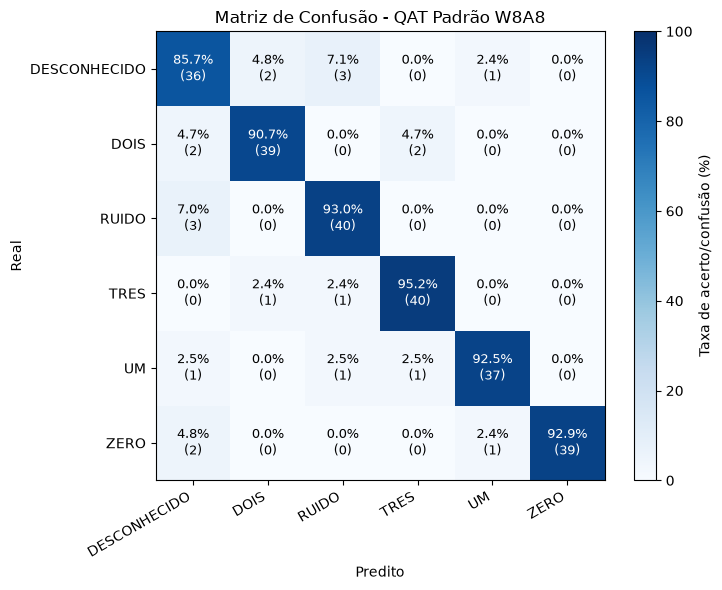


--- Treinando QAT Padrão (STE) W4A4 ---
Melhor Validação no QAT -> Acc: 92.86% | Loss: 0.2867
=== QAT Padrão W4A4 (252 amostras) ===
Accuracy                 : 89.68%
Loss                     : 0.4421
Area under ROC Curve     : 0.9890
Weighted avg Precision   : 0.9023
Weighted avg Recall      : 0.8968
Weighted avg F1 score    : 0.8966

F1 Score por classe:
  - desconhecido : 0.8052 (n=42)
  - dois         : 0.8864 (n=43)
  - ruido        : 0.8632 (n=43)
  - tres         : 0.9524 (n=42)
  - um           : 0.9250 (n=40)
  - zero         : 0.9500 (n=42)


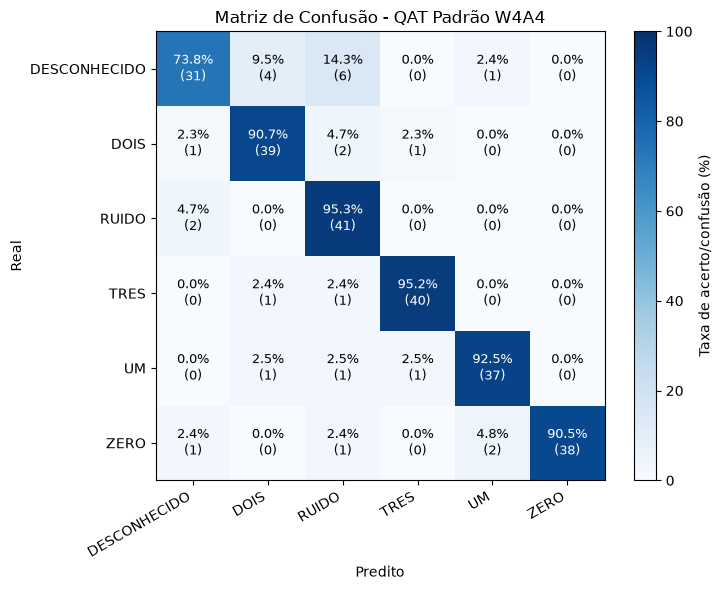


--- Treinando QAT Padrão (STE) W2A2 ---
Melhor Validação no QAT -> Acc: 89.52% | Loss: 0.3567
=== QAT Padrão W2A2 (252 amostras) ===
Accuracy                 : 85.32%
Loss                     : 0.5197
Area under ROC Curve     : 0.9765
Weighted avg Precision   : 0.8591
Weighted avg Recall      : 0.8532
Weighted avg F1 score    : 0.8540

F1 Score por classe:
  - desconhecido : 0.7901 (n=42)
  - dois         : 0.8941 (n=43)
  - ruido        : 0.8211 (n=43)
  - tres         : 0.8372 (n=42)
  - um           : 0.8684 (n=40)
  - zero         : 0.9136 (n=42)


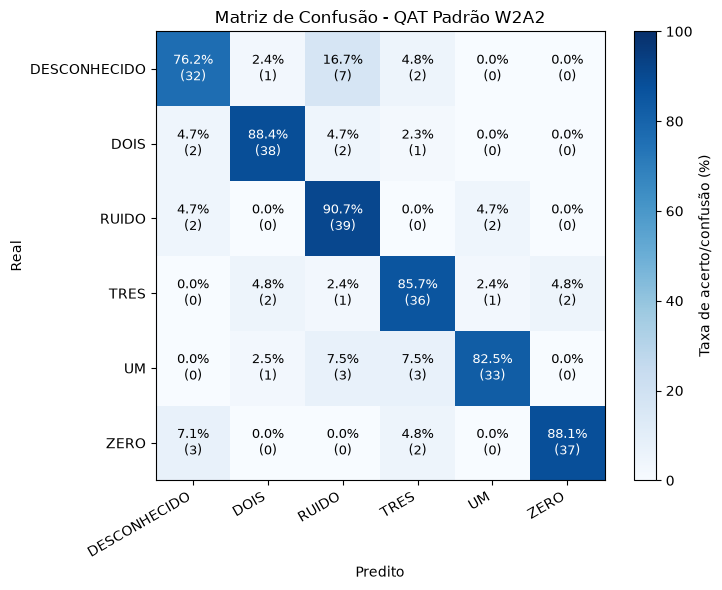


Modelo                   |  Acc (%) |     Loss |     AUC |    F1-W
------------------------------------------------------------------------
Baseline FP32            |   91.27% |   0.4191 |  0.9893 |  0.9131
PTQ W8A8 (MSE)           |   90.87% |   0.4162 |  0.9896 |  0.9090
QAT Padrão W8A8          |   91.67% |   0.4507 |  0.9884 |  0.9173
------------------------------------------------------------------------
PTQ W4A4 (MSE)           |   89.29% |   0.4882 |  0.9868 |  0.8929
QAT Padrão W4A4          |   89.68% |   0.4421 |  0.9890 |  0.8966
------------------------------------------------------------------------
PTQ W2A2 (MSE)           |   79.37% |   0.8546 |  0.9577 |  0.7955
QAT Padrão W2A2          |   85.32% |   0.5197 |  0.9765 |  0.8540
------------------------------------------------------------------------


In [14]:
class KWS_CNN_QAT_Padrao(nn.Module): 
    """QAT Padrão: pesos treináveis via STE, escalas fixas calibradas por MSE.""" 
    def __init__(self, modelo_fp32, escalas, num_bits):
        super().__init__()
        self.base = copy.deepcopy(modelo_fp32)

        # Registra as escalas como buffers fixos (não recebem gradiente aqui)
        for nome, val in escalas.items(): 
            self.register_buffer( 
                f"s_{nome}", torch.as_tensor(val, dtype=torch.float32).clone()
            )

        self.q_min_w, self.q_max_w = calcular_limites_inteiros(num_bits, signed=True)
        self.q_min_in, self.q_max_in = calcular_limites_inteiros(num_bits, signed=True)
        self.q_min_act, self.q_max_act = calcular_limites_inteiros(num_bits, signed=False)

    def forward(self, x): 
        # 1. Entrada MFCC quantizada (signed) 
        x = fake_quantize_uniforme(x, self.s_in, 0, self.q_min_in, self.q_max_in)

        # 2. Bloco 1: pesos quantizados na ida, gradiente STE na volta 
        w1_q = fake_quantize_uniforme(self.base.conv1.weight, self.s_w1, 0, self.q_min_w, self.q_max_w)
        x = F.conv1d( 
            x, w1_q, self.base.conv1.bias,
            stride=self.base.conv1.stride, padding=self.base.conv1.padding
        )
        x = self.base.relu1(x)
        x = fake_quantize_uniforme(x, self.s_a1, 0, self.q_min_act, self.q_max_act)
        x = self.base.drop1(self.base.pool1(x))

        # 3. Bloco 2
        w2_q = fake_quantize_uniforme(self.base.conv2.weight, self.s_w2, 0, self.q_min_w, self.q_max_w)
        x = F.conv1d(
            x, w2_q, self.base.conv2.bias,
            stride=self.base.conv2.stride, padding=self.base.conv2.padding 
        ) 
        x = self.base.relu2(x)
        x = fake_quantize_uniforme(x, self.s_a2, 0, self.q_min_act, self.q_max_act)
        x = self.base.drop2(self.base.pool2(x))

        # 4. Classificador                                                             
        x = self.base.flatten(x)
        wfc_q = fake_quantize_uniforme(self.base.fc.weight, self.s_wfc, 0, self.q_min_w, self.q_max_w)
        x = F.linear(x, wfc_q, self.base.fc.bias)
        return x


def treinar_qat(modelo_qat, train_loader, val_loader, criterion, device, epocas=100,   
lr=1e-3):
    """Fine-tuning QAT salvando o melhor estado na validação (sem tocar no teste)."""  
    optimizer = torch.optim.Adam(modelo_qat.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epocas,    
    eta_min=1e-5)

    melhor_val_acc = -1.0
    melhor_val_loss = float("inf")
    melhor_estado = None
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoca in range(1, epocas + 1):
        modelo_qat.train()
        soma_loss = 0.0
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            logits = modelo_qat(x_b)
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()
            soma_loss += loss.item() * x_b.size(0)
        scheduler.step()

        # Avaliação na validação
        modelo_qat.eval()
        val_loss, acertos, total = 0.0, 0, 0
        with torch.no_grad(): 
            for x_b, y_b in val_loader:
                x_b, y_b = x_b.to(device), y_b.to(device)
                logits = modelo_qat(x_b)
                val_loss += criterion(logits, y_b).item() * x_b.size(0)
                acertos += (logits.argmax(dim=1) == y_b).sum().item()
                total += y_b.size(0)

        t_loss = soma_loss / len(train_loader.dataset)
        v_loss = val_loss / total 
        v_acc = acertos / total
        hist["train_loss"].append(t_loss)
        hist["val_loss"].append(v_loss)
        hist["val_acc"].append(v_acc)

        if (v_acc > melhor_val_acc) or (v_acc == melhor_val_acc and v_loss <       
        melhor_val_loss):
            melhor_val_acc = v_acc
            melhor_val_loss = v_loss
            melhor_estado = copy.deepcopy(modelo_qat.state_dict())

    modelo_qat.load_state_dict(melhor_estado)
    print(f"Melhor Validação no QAT -> Acc: {melhor_val_acc*100:.2f}% | Loss: {melhor_val_loss:.4f}") 
    return modelo_qat, hist


# Executa QAT Normal (STE, escala fixa via MSE) para W8A8, W4A4 e W2A2
resultados_qat_padrao = {}
historicos_qat_padrao = {}

for bits in [8, 4, 2]:
    print(f"\n--- Treinando QAT Padrão (STE) W{bits}A{bits} ---")
    torch.manual_seed(42)

    escalas_mse = {
        "in":  calibrar_escala(ativacoes_calib["in"], bits, signed=True, metodo="mse"),
        "a1":  calibrar_escala(ativacoes_calib["a1"], bits, signed=False,            
        metodo="mse"),
        "a2":  calibrar_escala(ativacoes_calib["a2"], bits, signed=False,       
        metodo="mse"),
        "w1":  calibrar_escala(modelo_fp32_best.conv1.weight.data, bits, signed=True,  
        metodo="mse"), 
        "w2":  calibrar_escala(modelo_fp32_best.conv2.weight.data, bits, signed=True,
        metodo="mse"),
        "wfc": calibrar_escala(modelo_fp32_best.fc.weight.data, bits, signed=True,
        metodo="mse"),
    } 

    modelo_qat = KWS_CNN_QAT_Padrao(modelo_fp32_best, escalas_mse,
    num_bits=bits).to(device)
    modelo_qat, hist = treinar_qat(modelo_qat, train_loader, val_loader, criterion,
    device, epocas=100, lr=1e-3)

    nome_exp = f"QAT Padrão W{bits}A{bits}"
    historicos_qat_padrao[nome_exp] = hist
    resultados_qat_padrao[nome_exp] = avaliar_modelo(
        modelo_qat, test_loader, CLASSES, criterion, device,
        titulo=nome_exp, plotar_matriz=True
    )

# Tabela comparativa no Teste (252 amostras): Baseline vs PTQ (MSE) vs QAT Padrão      
print("\n" + "=" * 72)
print(f"{'Modelo':<24} | {'Acc (%)':>8} | {'Loss':>8} | {'AUC':>7} | {'F1-W':>7}")     
print("-" * 72)
print(f"{'Baseline FP32':<24} | {metricas_fp32_test['acc']*100:7.2f}% | {metricas_fp32_test['loss']:8.4f} | {metricas_fp32_test['auc']:7.4f} | {metricas_fp32_test['f1_w']:7.4f}")
for bits in [8, 4, 2]:
    m_ptq = resultados_ptq[f"PTQ W{bits}A{bits} (MSE)"]
    m_qat = resultados_qat_padrao[f"QAT Padrão W{bits}A{bits}"]
    print(f"{f'PTQ W{bits}A{bits} (MSE)':<24} | {m_ptq['acc']*100:7.2f}% | {m_ptq['loss']:8.4f} | {m_ptq['auc']:7.4f} | {m_ptq['f1_w']:7.4f}")
    print(f"{f'QAT Padrão W{bits}A{bits}':<24} | {m_qat['acc']*100:7.2f}% | {m_qat['loss']:8.4f} | {m_qat['auc']:7.4f} | {m_qat['f1_w']:7.4f}")
    print("-" * 72)

#### Análise dos Resultados — QAT Padrão

Os resultados no conjunto de teste (`252` amostras) confirmaram que a adaptação dos pesos durante o treinamento traz ganhos proporcionais à severidade da redução de bits:

- **W8A8:** apresentou comportamento equivalente ao *baseline* `FP32` (`91,67%` vs. `91,27%`), reforçando que 8 bits já preservam a capacidade representacional da rede mesmo sem ajuste fino significativo.
- **W4A4:** elevou discretamente a acurácia frente ao PTQ MSE (`89,29%` para `89,68%`), com melhora na calibração probabilística (*Loss* de `0,4882` para `0,4421` e *AUC* de `0,9868` para `0,9890`), permanecendo ainda `-1,59 p.p.` abaixo do `FP32` (principalmente pela confusão residual na classe `desconhecido`).
- **W2A2:** evidenciou o maior impacto do treinamento consciente de quantização, elevando a acurácia de `79,37%` (PTQ MSE) para `85,32%` (`+5,95 p.p.`), reduzindo o *Loss* de `0,8546` para `0,5197` e melhorando o *F1-Score* em todas as classes.

Apesar da recuperação expressiva em 2 bits, o *gap* remanescente de `-5,95 p.p.` em `W2A2` (e `-1,59 p.p.` em `W4A4`) evidencia a limitação de manter as escalas fixas: como os passos de quantização não são otimizados pelo gradiente, a grade discreta permanece rígida, motivando a avaliação seguinte com **LSQ** e **LSQ+**.

### 3.4 QAT com LSQ (Learned Step Size Quantization)

Como etapa seguinte à comparação com escala fixa, implementou-se o **LSQ** (*Learned Step Size Quantization*, conforme formulação revisitada em Bhalgat et al., 2020) em **8, 4 e 2 bits**, mantendo a inicialização das escalas pelo critério **MSE** (Bhalgat et al., 2020) e tornando o tamanho de passo `s` um parâmetro treinável via `nn.Parameter` em todos os 6 pontos de quantização (`in`, `w1`, `a1`, `w2`, `a2`, `wfc`). Aplicou-se o escalonamento de gradiente $g = 1/\sqrt{N \cdot Q_P}$ sobre `s` sob o mesmo protocolo de *fine-tuning* (`100` épocas, `Adam`, `CosineAnnealingLR` conforme Lin et al. (2023), seleção pela validação).


--- Treinando QAT LSQ W8A8 ---
Melhor Validação no QAT -> Acc: 92.86% | Loss: 0.2139
Escalas aprendidas (MSE inicial -> LSQ final):
  - in : 0.03460 -> 0.03520 (fator 1.02x)
  - a1 : 0.04002 -> 0.04006 (fator 1.00x)
  - a2 : 0.04487 -> 0.04288 (fator 0.96x)
  - w1 : 0.00874 -> 0.00896 (fator 1.03x)
  - w2 : 0.01819 -> 0.01788 (fator 0.98x)
  - wfc: 0.01348 -> 0.01370 (fator 1.02x)
=== QAT LSQ W8A8 (252 amostras) ===
Accuracy                 : 91.27%
Loss                     : 0.4580
Area under ROC Curve     : 0.9876
Weighted avg Precision   : 0.9138
Weighted avg Recall      : 0.9127
Weighted avg F1 score    : 0.9130

F1 Score por classe:
  - desconhecido : 0.8333 (n=42)
  - dois         : 0.8966 (n=43)
  - ruido        : 0.9195 (n=43)
  - tres         : 0.9286 (n=42)
  - um           : 0.9383 (n=40)
  - zero         : 0.9630 (n=42)


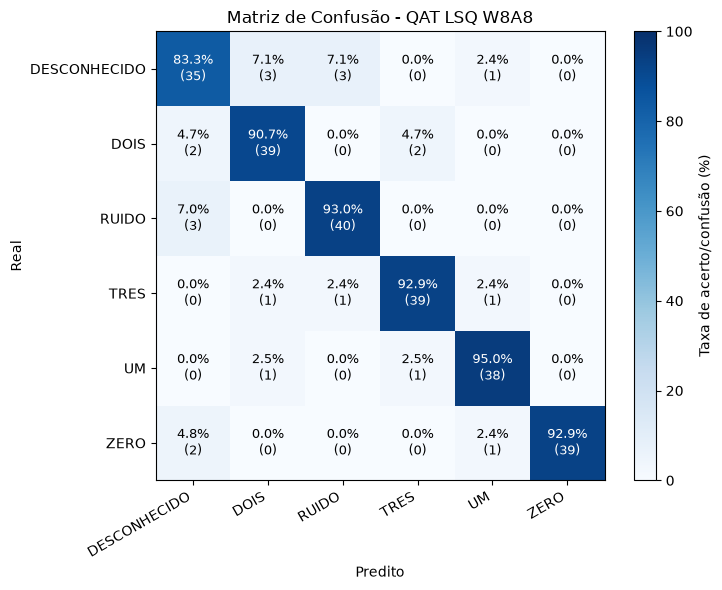


--- Treinando QAT LSQ W4A4 ---
Melhor Validação no QAT -> Acc: 92.86% | Loss: 0.2438
Escalas aprendidas (MSE inicial -> LSQ final):
  - in : 0.32816 -> 0.32041 (fator 0.98x)
  - a1 : 0.43824 -> 0.43228 (fator 0.99x)
  - a2 : 0.42923 -> 0.41592 (fator 0.97x)
  - w1 : 0.12421 -> 0.12477 (fator 1.00x)
  - w2 : 0.19972 -> 0.18479 (fator 0.93x)
  - wfc: 0.15826 -> 0.15041 (fator 0.95x)
=== QAT LSQ W4A4 (252 amostras) ===
Accuracy                 : 90.87%
Loss                     : 0.5068
Area under ROC Curve     : 0.9869
Weighted avg Precision   : 0.9112
Weighted avg Recall      : 0.9087
Weighted avg F1 score    : 0.9094

F1 Score por classe:
  - desconhecido : 0.8506 (n=42)
  - dois         : 0.8966 (n=43)
  - ruido        : 0.9091 (n=43)
  - tres         : 0.9268 (n=42)
  - um           : 0.9231 (n=40)
  - zero         : 0.9512 (n=42)


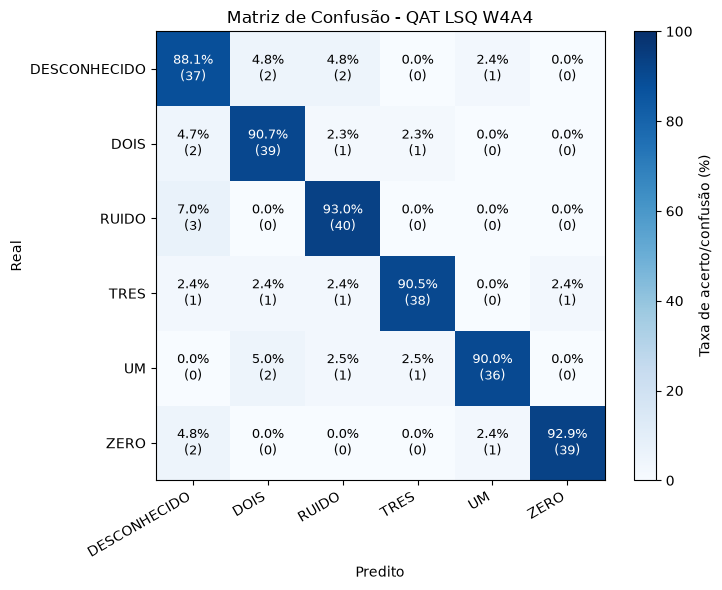


--- Treinando QAT LSQ W2A2 ---
Melhor Validação no QAT -> Acc: 91.43% | Loss: 0.3005
Escalas aprendidas (MSE inicial -> LSQ final):
  - in : 1.02273 -> 0.93482 (fator 0.91x)
  - a1 : 1.45774 -> 1.08182 (fator 0.74x)
  - a2 : 1.21040 -> 0.74407 (fator 0.61x)
  - w1 : 0.33831 -> 0.33059 (fator 0.98x)
  - w2 : 0.51587 -> 0.37233 (fator 0.72x)
  - wfc: 0.40366 -> 0.22545 (fator 0.56x)
=== QAT LSQ W2A2 (252 amostras) ===
Accuracy                 : 86.51%
Loss                     : 0.4037
Area under ROC Curve     : 0.9816
Weighted avg Precision   : 0.8722
Weighted avg Recall      : 0.8651
Weighted avg F1 score    : 0.8663

F1 Score por classe:
  - desconhecido : 0.7872 (n=42)
  - dois         : 0.9070 (n=43)
  - ruido        : 0.7901 (n=43)
  - tres         : 0.9048 (n=42)
  - um           : 0.8974 (n=40)
  - zero         : 0.9136 (n=42)


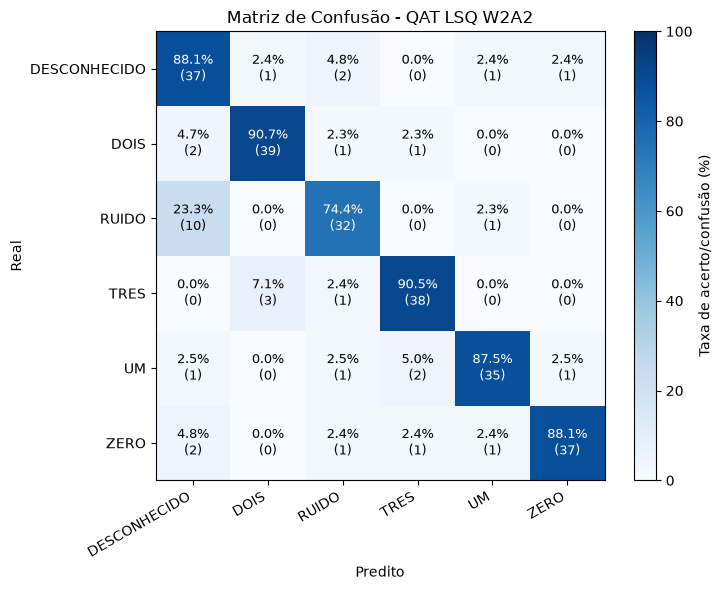


Modelo                   |  Acc (%) |     Loss |     AUC |    F1-W
------------------------------------------------------------------------
Baseline FP32            |   91.27% |   0.4191 |  0.9893 |  0.9131
PTQ W8A8 (MSE)           |   90.87% |   0.4162 |  0.9896 |  0.9090
QAT Padrão W8A8          |   91.67% |   0.4507 |  0.9884 |  0.9173
QAT LSQ W8A8             |   91.27% |   0.4580 |  0.9876 |  0.9130
------------------------------------------------------------------------
PTQ W4A4 (MSE)           |   89.29% |   0.4882 |  0.9868 |  0.8929
QAT Padrão W4A4          |   89.68% |   0.4421 |  0.9890 |  0.8966
QAT LSQ W4A4             |   90.87% |   0.5068 |  0.9869 |  0.9094
------------------------------------------------------------------------
PTQ W2A2 (MSE)           |   79.37% |   0.8546 |  0.9577 |  0.7955
QAT Padrão W2A2          |   85.32% |   0.5197 |  0.9765 |  0.8540
QAT LSQ W2A2             |   86.51% |   0.4037 |  0.9816 |  0.8663
-------------------------------------------

In [15]:
def grad_scale(x, scale):
    """Na ida retorna x; na volta multiplica o gradiente de x por scale."""
    return (x - x * scale).detach() + x * scale


class QuantizadorLSQ(nn.Module):
    """Quantizador LSQ: aprende o tamanho de passo s reutilizando
    fake_quantize_uniforme."""
    def __init__(self, num_bits, signed, escala_init):
        super().__init__()
        self.q_min, self.q_max = calcular_limites_inteiros(num_bits, signed=signed)    
        self.q_pos = max(1, abs(self.q_max))

        # s = s_init * escala_fator (inicia exatamente em s_init, com passo relativo estável no Adam)                                                               
        self.register_buffer("s_init", torch.as_tensor(escala_init,                    
        dtype=torch.float32).clone())
        self.escala_fator = nn.Parameter(torch.tensor(1.0, dtype=torch.float32))       

    def escala_atual(self):
        return self.s_init * torch.clamp(self.escala_fator, min=0.05)

    def forward(self, x):
        if self.training:
            with torch.no_grad():
                self.escala_fator.clamp_(min=0.05)
        g = 1.0 / math.sqrt(x.numel() * self.q_pos)
        s = grad_scale(self.escala_atual(), g)
        return fake_quantize_uniforme(x, s, 0, self.q_min, self.q_max)


class KWS_CNN_QAT(nn.Module):
    """Envolve KWS_CNN aplicando módulos quantizadores (LSQ ou LSQ+) nos 6 pontos."""  
    def __init__(self, modelo_fp32, quantizadores):
        super().__init__()
        self.base = copy.deepcopy(modelo_fp32)
        self.q = nn.ModuleDict(quantizadores)

    def forward(self, x):
        # 1. Entrada MFCC
        x = self.q["in"](x)

        # 2. Bloco 1                                                                   
        w1_q = self.q["w1"](self.base.conv1.weight)
        x = F.conv1d(
            x, w1_q, self.base.conv1.bias,
            stride=self.base.conv1.stride, padding=self.base.conv1.padding
        )
        x = self.q["a1"](self.base.relu1(x))
        x = self.base.drop1(self.base.pool1(x))

        # 3. Bloco 2
        w2_q = self.q["w2"](self.base.conv2.weight)
        x = F.conv1d(
            x, w2_q, self.base.conv2.bias,
            stride=self.base.conv2.stride, padding=self.base.conv2.padding             
        )
        x = self.q["a2"](self.base.relu2(x))
        x = self.base.drop2(self.base.pool2(x))

        # 4. Classificador
        x = self.base.flatten(x)
        wfc_q = self.q["wfc"](self.base.fc.weight)
        x = F.linear(x, wfc_q, self.base.fc.bias)
        return x


# Executa QAT com LSQ para W8A8, W4A4 e W2A2
resultados_lsq = {}
historicos_lsq = {}

for bits in [8, 4, 2]:
    print(f"\n--- Treinando QAT LSQ W{bits}A{bits} ---")
    torch.manual_seed(42)

    quantizadores_lsq = {
        "in":  QuantizadorLSQ(bits, signed=True,
            escala_init=calibrar_escala(ativacoes_calib["in"], bits, signed=True,         
        metodo="mse")), 
        "a1":  QuantizadorLSQ(bits, signed=False,
        escala_init=calibrar_escala(ativacoes_calib["a1"], bits, signed=False,       
        metodo="mse")),
        "a2":  QuantizadorLSQ(bits, signed=False,
        escala_init=calibrar_escala(ativacoes_calib["a2"], bits, signed=False,   
        metodo="mse")), 
        "w1":  QuantizadorLSQ(bits, signed=True,
            escala_init=calibrar_escala(modelo_fp32_best.conv1.weight.data, bits, 
        signed=True, metodo="mse")),
        "w2":  QuantizadorLSQ(bits, signed=True,
            escala_init=calibrar_escala(modelo_fp32_best.conv2.weight.data, bits,     
        signed=True, metodo="mse")),
        "wfc": QuantizadorLSQ(bits, signed=True,
            escala_init=calibrar_escala(modelo_fp32_best.fc.weight.data, bits,    
        signed=True, metodo="mse")), 
    }

    modelo_lsq = KWS_CNN_QAT(modelo_fp32_best, quantizadores_lsq).to(device) 
    modelo_lsq, hist = treinar_qat(modelo_lsq, train_loader, val_loader, criterion,
    device, epocas=100, lr=1e-3)

    # Mostra quanto as escalas s se ajustaram em relação ao MSE inicial
    print("Escalas aprendidas (MSE inicial -> LSQ final):")
    for nome_q, mod_q in modelo_lsq.q.items():
        s0 = mod_q.s_init.item()
        sf = mod_q.escala_atual().item()
        print(f"  - {nome_q:<3}: {s0:.5f} -> {sf:.5f} (fator {sf/s0:.2f}x)") 

    nome_exp = f"QAT LSQ W{bits}A{bits}"
    historicos_lsq[nome_exp] = hist
    resultados_lsq[nome_exp] = avaliar_modelo(
        modelo_lsq, test_loader, CLASSES, criterion, device,
        titulo=nome_exp, plotar_matriz=True
    )

# Tabela comparativa acumulada no Teste (252 amostras)
print("\n" + "=" * 72)
print(f"{'Modelo':<24} | {'Acc (%)':>8} | {'Loss':>8} | {'AUC':>7} | {'F1-W':>7}")
print("-" * 72)
print(f"{'Baseline FP32':<24} | {metricas_fp32_test['acc']*100:7.2f}% | {metricas_fp32_test['loss']:8.4f} | {metricas_fp32_test['auc']:7.4f} | {metricas_fp32_test['f1_w']:7.4f}")
for bits in [8, 4, 2]:
    m_ptq = resultados_ptq[f"PTQ W{bits}A{bits} (MSE)"]
    m_pad = resultados_qat_padrao[f"QAT Padrão W{bits}A{bits}"]
    m_lsq = resultados_lsq[f"QAT LSQ W{bits}A{bits}"]
    print(f"{f'PTQ W{bits}A{bits} (MSE)':<24} | {m_ptq['acc']*100:7.2f}% | {m_ptq['loss']:8.4f} | {m_ptq['auc']:7.4f} | {m_ptq['f1_w']:7.4f}")
    print(f"{f'QAT Padrão W{bits}A{bits}':<24} | {m_pad['acc']*100:7.2f}% | {m_pad['loss']:8.4f} | {m_pad['auc']:7.4f} | {m_pad['f1_w']:7.4f}")
    print(f"{f'QAT LSQ W{bits}A{bits}':<24} | {m_lsq['acc']*100:7.2f}% | {m_lsq['loss']:8.4f} | {m_lsq['auc']:7.4f} | {m_lsq['f1_w']:7.4f}")
    print("-" * 72)

#### Análise dos Resultados — QAT LSQ

A inclusão do tamanho de passo aprendível (`s`) produziu ganhos consistentes nas precisões sub-8-bit frente ao QAT Padrão (escala fixa):

- **W8A8:** manteve estabilidade total, com fatores de ajuste próximos à unidade (`0,96x` a `1,03x`) e empate técnico com o *baseline* `FP32` (`91,27%`, `F1-W = 0,9130`).
- **W4A4:** elevou a acurácia no teste para `90,87%` (`+1,19 p.p.` sobre o QAT Padrão e apenas `-0,40 p.p.` abaixo do `FP32`), impulsionado pela forte recuperação da classe `desconhecido` (`73,8%` $\rightarrow$ `88,1%`, `F1 = 0,8506`) mediante ajustes finos de escala (`0,93x` a `1,00x`).
- **W2A2:** atingiu `86,51%` de acurácia (`+1,19 p.p.` sobre o QAT Padrão e `+7,14 p.p.` sobre o PTQ MSE), com redução expressiva do *Loss* (`0,5197` $\rightarrow$ `0,4037`) e aumento de *AUC* (`0,9816`). Observou-se que o otimizador contraiu sistematicamente as escalas internas (`a1: 0,74x`, `a2: 0,61x`, `w2: 0,72x`, `wfc: 0,56x`), priorizando maior resolução na região central da distribuição em detrimento das caudas.

Ainda assim, remanesceu em `W2A2` um desbalanceamento na distinção entre `ruido` (`74,4%` de acerto, com `23,3%` confundido com `desconhecido`) e uma rigidez na entrada `MFCC` (`in: 0,91x`) devido à restrição simétrica em torno de zero.

### 3.5 QAT com LSQ+ (Learned Step Size + Offset)

Implementou-se o **LSQ+** (Bhalgat et al., 2020) em **8, 4 e 2 bits** sobre a mesma arquitetura `KWS_CNN_QAT` e protocolo de *fine-tuning* (`100` épocas, `Adam`, `CosineAnnealingLR`). Conforme recomendado pelos autores, os pesos (`w1`, `w2`, `wfc`) mantiveram quantização simétrica com sinal via `QuantizadorLSQ` (sem custo extra de inferência), enquanto a entrada MFCC (`in`, assimétrica pós-CMVN) e as ativações (`a1`, `a2`) passaram a utilizar `QuantizadorLSQPlus` na parametrização *Unsigned + Asymmetric* ($[0,\, 2^b-1]$) com `s` e `beta` treináveis, inicializados conjuntamente pela minimização do **MSE** sobre o conjunto de treino (`840` amostras).


--- Treinando QAT LSQ+ W8A8 ---
Melhor Validação no QAT -> Acc: 92.86% | Loss: 0.2186
Parâmetros aprendidos no LSQ+ (inicial -> final):
  - in : s=0.0397->0.0382 (0.96x) | beta=-6.0951->-6.0961
  - a1 : s=0.0401->0.0423 (1.05x) | beta=-0.0042->-0.0042
  - a2 : s=0.0453->0.0476 (1.05x) | beta=-0.0057->-0.0057
  - w1 : s=0.0087->0.0088 (1.01x) | beta=0 (simétrico)
  - w2 : s=0.0182->0.0178 (0.98x) | beta=0 (simétrico)
  - wfc: s=0.0135->0.0132 (0.98x) | beta=0 (simétrico)
=== QAT LSQ+ W8A8 (252 amostras) ===
Accuracy                 : 90.48%
Loss                     : 0.4450
Area under ROC Curve     : 0.9883
Weighted avg Precision   : 0.9055
Weighted avg Recall      : 0.9048
Weighted avg F1 score    : 0.9048

F1 Score por classe:
  - desconhecido : 0.8333 (n=42)
  - dois         : 0.8966 (n=43)
  - ruido        : 0.9195 (n=43)
  - tres         : 0.9024 (n=42)
  - um           : 0.9268 (n=40)
  - zero         : 0.9512 (n=42)


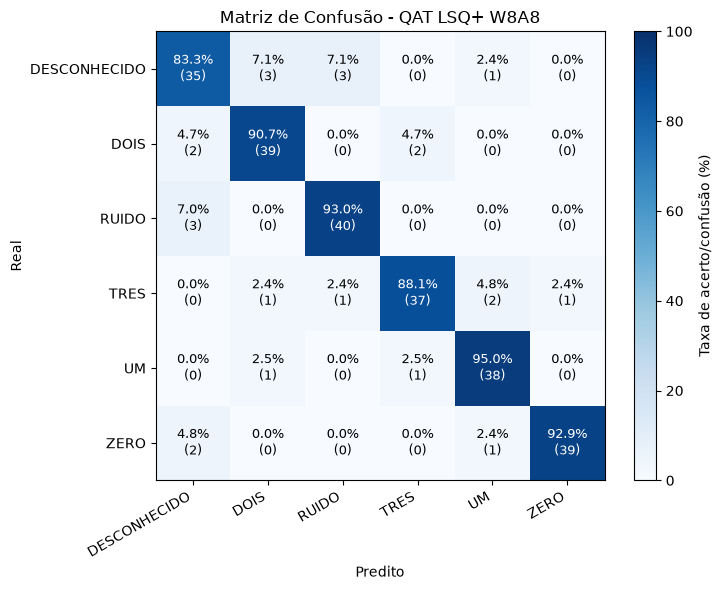


--- Treinando QAT LSQ+ W4A4 ---
Melhor Validação no QAT -> Acc: 93.33% | Loss: 0.2203
Parâmetros aprendidos no LSQ+ (inicial -> final):
  - in : s=0.4363->0.4290 (0.98x) | beta=-4.2058->-4.1744
  - a1 : s=0.4371->0.3989 (0.91x) | beta=0.0009->0.0042
  - a2 : s=0.3937->0.3703 (0.94x) | beta=-0.0453->-0.0509
  - w1 : s=0.1242->0.1194 (0.96x) | beta=0 (simétrico)
  - w2 : s=0.1997->0.1527 (0.76x) | beta=0 (simétrico)
  - wfc: s=0.1583->0.1167 (0.74x) | beta=0 (simétrico)
=== QAT LSQ+ W4A4 (252 amostras) ===
Accuracy                 : 90.08%
Loss                     : 0.5133
Area under ROC Curve     : 0.9851
Weighted avg Precision   : 0.9023
Weighted avg Recall      : 0.9008
Weighted avg F1 score    : 0.9007

F1 Score por classe:
  - desconhecido : 0.8049 (n=42)
  - dois         : 0.9213 (n=43)
  - ruido        : 0.8889 (n=43)
  - tres         : 0.9136 (n=42)
  - um           : 0.9250 (n=40)
  - zero         : 0.9512 (n=42)


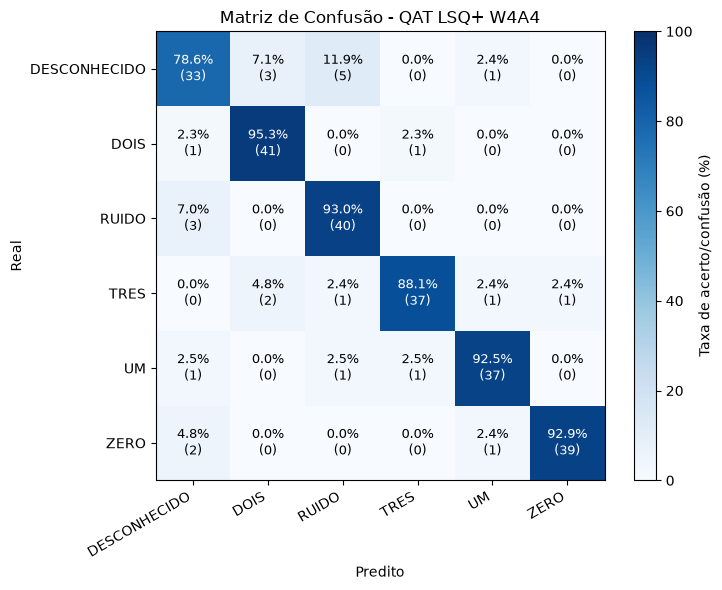


--- Treinando QAT LSQ+ W2A2 ---
Melhor Validação no QAT -> Acc: 90.00% | Loss: 0.3046
Parâmetros aprendidos no LSQ+ (inicial -> final):
  - in : s=1.0227->0.9731 (0.95x) | beta=-1.6104->-1.5442
  - a1 : s=1.2820->1.0915 (0.85x) | beta=0.1867->-0.0003
  - a2 : s=0.7380->0.6404 (0.87x) | beta=0.2149->0.0633
  - w1 : s=0.3383->0.3140 (0.93x) | beta=0 (simétrico)
  - w2 : s=0.5159->0.3869 (0.75x) | beta=0 (simétrico)
  - wfc: s=0.4037->0.2345 (0.58x) | beta=0 (simétrico)
=== QAT LSQ+ W2A2 (252 amostras) ===
Accuracy                 : 83.33%
Loss                     : 0.4992
Area under ROC Curve     : 0.9736
Weighted avg Precision   : 0.8396
Weighted avg Recall      : 0.8333
Weighted avg F1 score    : 0.8353

F1 Score por classe:
  - desconhecido : 0.7692 (n=42)
  - dois         : 0.8941 (n=43)
  - ruido        : 0.6897 (n=43)
  - tres         : 0.8780 (n=42)
  - um           : 0.8312 (n=40)
  - zero         : 0.9512 (n=42)


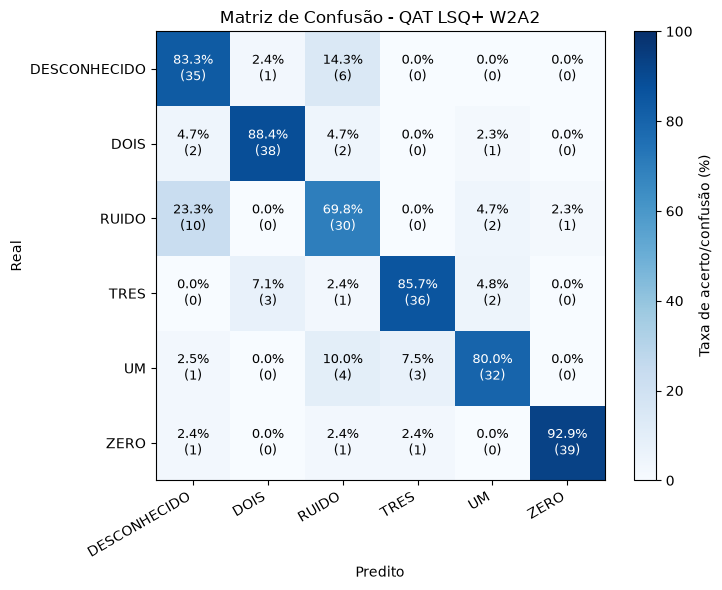


Modelo                   |  Acc (%) |     Loss |     AUC |    F1-W
------------------------------------------------------------------------
Baseline FP32            |   91.27% |   0.4191 |  0.9893 |  0.9131
------------------------------------------------------------------------
PTQ W8A8 (MSE)           |   90.87% |   0.4162 |  0.9896 |  0.9090
QAT Padrão W8A8          |   91.67% |   0.4507 |  0.9884 |  0.9173
QAT LSQ W8A8             |   91.27% |   0.4580 |  0.9876 |  0.9130
QAT LSQ+ W8A8            |   90.48% |   0.4450 |  0.9883 |  0.9048
------------------------------------------------------------------------
PTQ W4A4 (MSE)           |   89.29% |   0.4882 |  0.9868 |  0.8929
QAT Padrão W4A4          |   89.68% |   0.4421 |  0.9890 |  0.8966
QAT LSQ W4A4             |   90.87% |   0.5068 |  0.9869 |  0.9094
QAT LSQ+ W4A4            |   90.08% |   0.5133 |  0.9851 |  0.9007
------------------------------------------------------------------------
PTQ W2A2 (MSE)           |   79.37% |

In [16]:
class QuantizadorLSQPlus(QuantizadorLSQ):
    """Extensão LSQ+: herda s do QuantizadorLSQ e adiciona offset assimétrico beta
    aprendível."""
    def __init__(self, num_bits, signed, escala_init, beta_init=0.0):
        super().__init__(num_bits, signed=signed, escala_init=escala_init)
        self.register_buffer("beta_init", torch.as_tensor(beta_init,
        dtype=torch.float32).clone()) 
        self.beta_desloc = nn.Parameter(torch.tensor(0.0, dtype=torch.float32))

    def beta_atual(self): 
        return self.beta_init + self.s_init * self.beta_desloc 

    def forward(self, x):
        if self.training:
            with torch.no_grad():
                self.escala_fator.clamp_(min=0.05)
        g = 1.0 / math.sqrt(x.numel() * self.q_pos) 
        s = grad_scale(self.escala_atual(), g) 
        b = grad_scale(self.beta_atual(), g)
        return fake_quantize_uniforme(x, s, -b / s, self.q_min, self.q_max) 


def calibrar_lsq_plus_mse(tensor, num_bits, signed=False, passos=80): 
    """Inicializa (s_init, beta_init) minimizando o MSE via autograd."""
    q_min, q_max = calcular_limites_inteiros(num_bits, signed=signed)
    # Amostra determinística de até 50 mil pontos ao longo de todo o conjunto de treino para agilizar na CPU
    plano = tensor.reshape(-1)
    passo = max(1, plano.numel() // 50_000) 
    x_sub = plano[::passo].detach() 

    x_min = x_sub.min() 
    x_max = x_sub.max() 
    s0 = torch.clamp((x_max - x_min) / (q_max - q_min), min=1e-6)
    b0 = x_min - q_min * s0

    s_fator = torch.tensor(1.0, device=x_sub.device, requires_grad=True)
    b_desloc = torch.tensor(0.0, device=x_sub.device, requires_grad=True)
    opt = torch.optim.Adam([s_fator, b_desloc], lr=0.05) 

    for _ in range(passos):
        opt.zero_grad()
        s_cand = torch.clamp(s0 * s_fator, min=1e-6)
        b_cand = b0 + s0 * b_desloc 
        q_cand = fake_quantize_uniforme(x_sub, s_cand, -b_cand / s_cand, q_min, q_max) 
        loss = torch.mean((q_cand - x_sub) ** 2)
        loss.backward()
        opt.step()

    with torch.no_grad(): 
        s_final = torch.clamp(s0 * s_fator, min=1e-6).detach()
        b_final = (b0 + s0 * b_desloc).detach()
    return s_final, b_final


# Executa QAT com LSQ+ para W8A8, W4A4 e W2A2
resultados_lsq_plus = {}
historicos_lsq_plus = {}

for bits in [8, 4, 2]:
    print(f"\n--- Treinando QAT LSQ+ W{bits}A{bits} ---")
    torch.manual_seed(42)

    s_in, b_in = calibrar_lsq_plus_mse(ativacoes_calib["in"], bits, signed=False)
    s_a1, b_a1 = calibrar_lsq_plus_mse(ativacoes_calib["a1"], bits, signed=False)
    s_a2, b_a2 = calibrar_lsq_plus_mse(ativacoes_calib["a2"], bits, signed=False)

    quantizadores_lsq_plus = { 
        "in":  QuantizadorLSQPlus(bits, signed=False, escala_init=s_in,         
        beta_init=b_in),
        "a1":  QuantizadorLSQPlus(bits, signed=False, escala_init=s_a1,
        beta_init=b_a1),
        "a2":  QuantizadorLSQPlus(bits, signed=False, escala_init=s_a2,           
        beta_init=b_a2),
        "w1":  QuantizadorLSQ(bits, signed=True,
        escala_init=calibrar_escala(modelo_fp32_best.conv1.weight.data, bits,       
        signed=True, metodo="mse")),
        "w2":  QuantizadorLSQ(bits, signed=True,
        escala_init=calibrar_escala(modelo_fp32_best.conv2.weight.data, bits,    
        signed=True, metodo="mse")), 
        "wfc": QuantizadorLSQ(bits, signed=True,
        escala_init=calibrar_escala(modelo_fp32_best.fc.weight.data, bits, signed=True,
        metodo="mse")), 
    }

    modelo_lsqp = KWS_CNN_QAT(modelo_fp32_best, quantizadores_lsq_plus).to(device)
    modelo_lsqp, hist = treinar_qat(modelo_lsqp, train_loader, val_loader, criterion,  
    device, epocas=100, lr=1e-3) 

    print("Parâmetros aprendidos no LSQ+ (inicial -> final):")
    for nome_q, mod_q in modelo_lsqp.q.items():
        s0, sf = mod_q.s_init.item(), mod_q.escala_atual().item() 
        if isinstance(mod_q, QuantizadorLSQPlus):
            b0, bf = mod_q.beta_init.item(), mod_q.beta_atual().item() 
            print(f"  - {nome_q:<3}: s={s0:.4f}->{sf:.4f} ({sf/s0:.2f}x) | beta={b0:.4f}->{bf:.4f}")
        else:
            print(f"  - {nome_q:<3}: s={s0:.4f}->{sf:.4f} ({sf/s0:.2f}x) | beta=0 (simétrico)")

    nome_exp = f"QAT LSQ+ W{bits}A{bits}"
    historicos_lsq_plus[nome_exp] = hist
    resultados_lsq_plus[nome_exp] = avaliar_modelo( 
        modelo_lsqp, test_loader, CLASSES, criterion, device,
        titulo=nome_exp, plotar_matriz=True 
    )

# Tabela comparativa completa no Teste (252 amostras): Baseline -> PTQ -> QAT Padrão -> LSQ -> LSQ+ 
print("\n" + "=" * 72) 
print(f"{'Modelo':<24} | {'Acc (%)':>8} | {'Loss':>8} | {'AUC':>7} | {'F1-W':>7}")
print("-" * 72) 
print(f"{'Baseline FP32':<24} | {metricas_fp32_test['acc']*100:7.2f}% | {metricas_fp32_test['loss']:8.4f} | {metricas_fp32_test['auc']:7.4f} | {metricas_fp32_test['f1_w']:7.4f}") 
print("-" * 72)
for bits in [8, 4, 2]:
    m_ptq  = resultados_ptq[f"PTQ W{bits}A{bits} (MSE)"] 
    m_pad  = resultados_qat_padrao[f"QAT Padrão W{bits}A{bits}"]
    m_lsq  = resultados_lsq[f"QAT LSQ W{bits}A{bits}"]
    m_lsqp = resultados_lsq_plus[f"QAT LSQ+ W{bits}A{bits}"]
    print(f"{f'PTQ W{bits}A{bits} (MSE)':<24} | {m_ptq['acc']*100:7.2f}% | {m_ptq['loss']:8.4f} | {m_ptq['auc']:7.4f} | {m_ptq['f1_w']:7.4f}")
    print(f"{f'QAT Padrão W{bits}A{bits}':<24} | {m_pad['acc']*100:7.2f}% | {m_pad['loss']:8.4f} | {m_pad['auc']:7.4f} | {m_pad['f1_w']:7.4f}")
    print(f"{f'QAT LSQ W{bits}A{bits}':<24} | {m_lsq['acc']*100:7.2f}% | {m_lsq['loss']:8.4f} | {m_lsq['auc']:7.4f} | {m_lsq['f1_w']:7.4f}")
    print(f"{f'QAT LSQ+ W{bits}A{bits}':<24} | {m_lsqp['acc']*100:7.2f}% | {m_lsqp['loss']:8.4f} | {m_lsqp['auc']:7.4f} | {m_lsqp['f1_w']:7.4f}")             
    print("-" * 72)


#### Análise dos Resultados — QAT LSQ+

Em vez de superar o `LSQ`, a adição do *offset* aprendível $\beta$ no `LSQ+` reduziu o desempenho no conjunto de teste em todas as precisões (`91,27%` $\rightarrow$ `90,48%` em `W8A8`; `90,87%` $\rightarrow$ `90,08%` em `W4A4`; e `86,51%` $\rightarrow$ `83,33%` em `W2A2`, com queda da classe `ruido` para `69,8%`).

Sob a ótica de **Otimização Não-Convexas e Geometria da `ReLU`**, os parâmetros aprendidos explicam exatamente esse fenômeno:

1. **Deslocamento de zero (*Zero-Point Drift*) na fronteira da `ReLU`:** as ativações `a1` e `a2` são restringidas por `ReLU` ao cone não-negativo ($\mathbb{R}_+$), concentrando grande massa de valores exatamente em $v = 0$. Ao inicializar $\beta$ pelo MSE sem restrição em `W2A2`, obteve-se $\beta_{\text{init}} = +0{,}1867$ (`a1`) e $+0{,}2149$ (`a2`), deslocando o menor nível discreto ($q=0$) para fora de zero e injetando viés positivo constante sobre neurônios inativos. Durante o treino, o próprio gradiente tentou reverter esse desvio (`a1`: $+0{,}1867 \rightarrow -0{,}0003$), gerando acoplamento mal-condicionado entre $s$ e $\beta$ sob gradientes aproximados via STE.
2. **Perda do nível `0,0` na entrada MFCC normalizada:** como os coeficientes MFCC pós-CMVN possuem média $\approx 0$, a grade assimétrica do `LSQ+` em `W2A2` (`[-1,54; -0,57; +0,40; +1,38]`) deixou de conter o valor exato `0,00` (presente no `LSQ` simétrico `[-1,87; -0,93; 0,00; +0,93]`), prejudicando a separação de sinais de baixa energia (`ruido` vs. `desconhecido`).

### 3.6 QAT com LSQ+ Híbrido (Projeção da Restrição $\beta = 0$ pós-ReLU)

Para investigar se a queda do `LSQ+` decorreu especificamente da violação do zero exato nas ativações pós-`ReLU` (`a1` e `a2`), implementa-se uma variante híbrida baseada em **projeção sobre a restrição de fronteira** (Antoniou & Lu, 2007; Souza, 2026): mantém-se $\beta = 0$ nas ativações `a1` e `a2` (`QuantizadorLSQ`, preservando o alinhamento exato do nível $q = 0$ com `0,0`) e aplica-se o *offset* aprendível $\beta$ (`QuantizadorLSQPlus`) exclusivamente na entrada MFCC normalizada (`in`, que apresenta distribuição assimétrica com valores negativos e positivos reais entre `-6,362` e `+5,051`, cenário em que Bhalgat et al. (2020) apontam vantagem da quantização assimétrica com *offset*). Mantém-se exatamente o mesmo protocolo de *fine-tuning* (`100` épocas, `Adam`, `CosineAnnealingLR`, *seed* `42`).


--- Treinando QAT LSQ+ Híbrido W8A8 ---
Melhor Validação no QAT -> Acc: 92.86% | Loss: 0.2070
Parâmetros aprendidos no LSQ+ Híbrido (inicial -> final):
  - in : s=0.0397->0.0374 (0.94x) | beta=-6.0951->-6.0966
  - a1 : s=0.0400->0.0398 (1.00x) | beta=0 (projetado/simétrico)
  - a2 : s=0.0449->0.0441 (0.98x) | beta=0 (projetado/simétrico)
  - w1 : s=0.0087->0.0089 (1.01x) | beta=0 (projetado/simétrico)
  - w2 : s=0.0182->0.0172 (0.94x) | beta=0 (projetado/simétrico)
  - wfc: s=0.0135->0.0136 (1.01x) | beta=0 (projetado/simétrico)
=== QAT LSQ+ Híb W8A8 (252 amostras) ===
Accuracy                 : 90.48%
Loss                     : 0.4556
Area under ROC Curve     : 0.9885
Weighted avg Precision   : 0.9071
Weighted avg Recall      : 0.9048
Weighted avg F1 score    : 0.9052

F1 Score por classe:
  - desconhecido : 0.8095 (n=42)
  - dois         : 0.9176 (n=43)
  - ruido        : 0.8889 (n=43)
  - tres         : 0.9412 (n=42)
  - um           : 0.9250 (n=40)
  - zero         : 0.9500 (n=42)

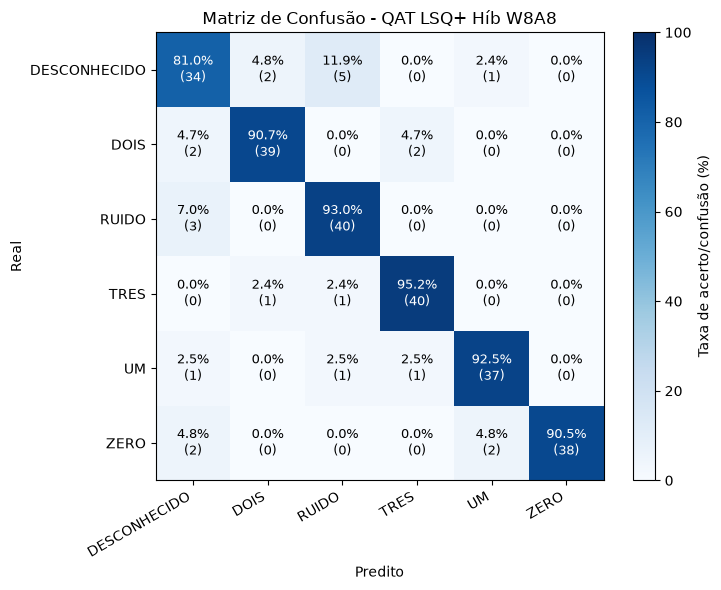


--- Treinando QAT LSQ+ Híbrido W4A4 ---
Melhor Validação no QAT -> Acc: 93.81% | Loss: 0.2713
Parâmetros aprendidos no LSQ+ Híbrido (inicial -> final):
  - in : s=0.4363->0.4315 (0.99x) | beta=-4.2058->-4.2053
  - a1 : s=0.4382->0.4318 (0.99x) | beta=0 (projetado/simétrico)
  - a2 : s=0.4292->0.4232 (0.99x) | beta=0 (projetado/simétrico)
  - w1 : s=0.1242->0.1257 (1.01x) | beta=0 (projetado/simétrico)
  - w2 : s=0.1997->0.1933 (0.97x) | beta=0 (projetado/simétrico)
  - wfc: s=0.1583->0.1550 (0.98x) | beta=0 (projetado/simétrico)
=== QAT LSQ+ Híb W4A4 (252 amostras) ===
Accuracy                 : 88.49%
Loss                     : 0.4764
Area under ROC Curve     : 0.9862
Weighted avg Precision   : 0.8898
Weighted avg Recall      : 0.8849
Weighted avg F1 score    : 0.8861

F1 Score por classe:
  - desconhecido : 0.7955 (n=42)
  - dois         : 0.8764 (n=43)
  - ruido        : 0.8837 (n=43)
  - tres         : 0.8861 (n=42)
  - um           : 0.9136 (n=40)
  - zero         : 0.9630 (n=42)

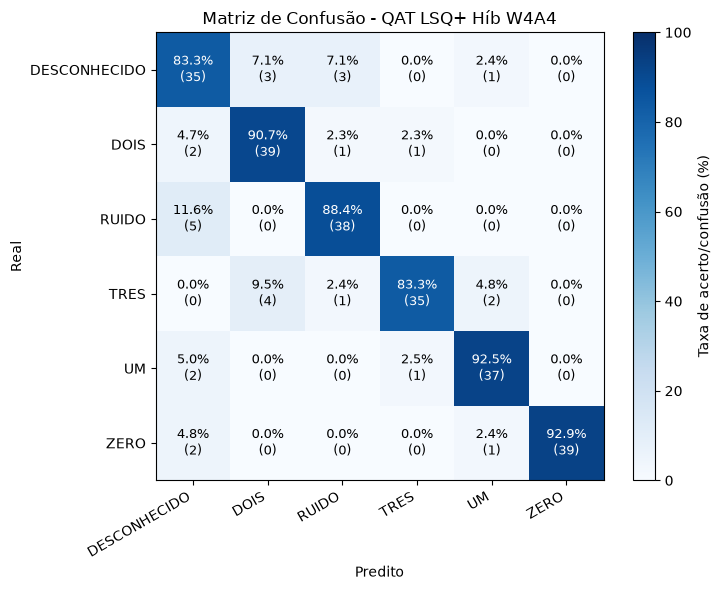


--- Treinando QAT LSQ+ Híbrido W2A2 ---
Melhor Validação no QAT -> Acc: 90.00% | Loss: 0.3246
Parâmetros aprendidos no LSQ+ Híbrido (inicial -> final):
  - in : s=1.0227->0.9563 (0.94x) | beta=-1.6104->-1.5587
  - a1 : s=1.4577->1.0842 (0.74x) | beta=0 (projetado/simétrico)
  - a2 : s=1.2104->0.7598 (0.63x) | beta=0 (projetado/simétrico)
  - w1 : s=0.3383->0.3143 (0.93x) | beta=0 (projetado/simétrico)
  - w2 : s=0.5159->0.3825 (0.74x) | beta=0 (projetado/simétrico)
  - wfc: s=0.4037->0.2325 (0.58x) | beta=0 (projetado/simétrico)
=== QAT LSQ+ Híb W2A2 (252 amostras) ===
Accuracy                 : 85.32%
Loss                     : 0.4703
Area under ROC Curve     : 0.9765
Weighted avg Precision   : 0.8549
Weighted avg Recall      : 0.8532
Weighted avg F1 score    : 0.8528

F1 Score por classe:
  - desconhecido : 0.8095 (n=42)
  - dois         : 0.8916 (n=43)
  - ruido        : 0.8140 (n=43)
  - tres         : 0.8667 (n=42)
  - um           : 0.8158 (n=40)
  - zero         : 0.9176 (n=42)

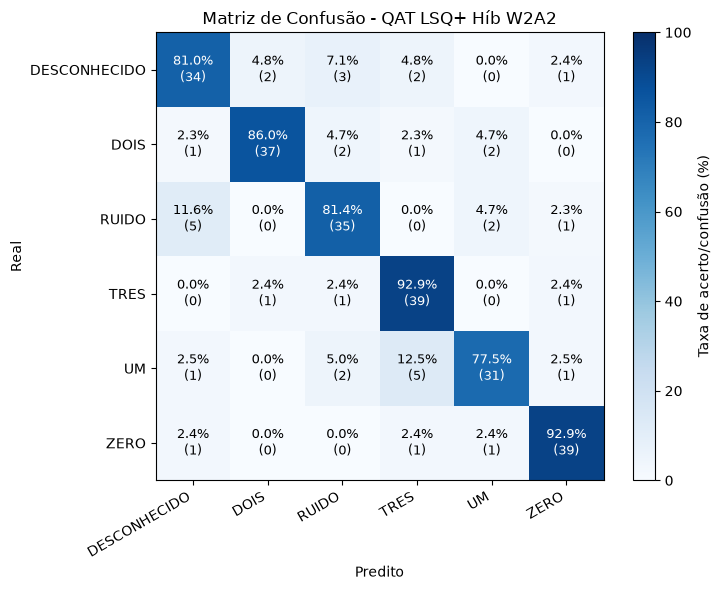


Modelo                   |  Acc (%) |     Loss |     AUC |    F1-W
------------------------------------------------------------------------
Baseline FP32            |   91.27% |   0.4191 |  0.9893 |  0.9131
------------------------------------------------------------------------
QAT LSQ W8A8             |   91.27% |   0.4580 |  0.9876 |  0.9130
QAT LSQ+ W8A8            |   90.48% |   0.4450 |  0.9883 |  0.9048
QAT LSQ+ Híb W8A8        |   90.48% |   0.4556 |  0.9885 |  0.9052
------------------------------------------------------------------------
QAT LSQ W4A4             |   90.87% |   0.5068 |  0.9869 |  0.9094
QAT LSQ+ W4A4            |   90.08% |   0.5133 |  0.9851 |  0.9007
QAT LSQ+ Híb W4A4        |   88.49% |   0.4764 |  0.9862 |  0.8861
------------------------------------------------------------------------
QAT LSQ W2A2             |   86.51% |   0.4037 |  0.9816 |  0.8663
QAT LSQ+ W2A2            |   83.33% |   0.4992 |  0.9736 |  0.8353
QAT LSQ+ Híb W2A2        |   85.32% |

In [17]:
# Executa QAT LSQ+ Híbrido (beta=0 projetado em a1/a2; beta aprendível apenas em 'in')
resultados_lsq_plus_hib = {}
historicos_lsq_plus_hib = {}

for bits in [8, 4, 2]:
    print(f"\n--- Treinando QAT LSQ+ Híbrido W{bits}A{bits} ---")
    torch.manual_seed(42)

    s_in, b_in = calibrar_lsq_plus_mse(ativacoes_calib["in"], bits, signed=False)

    quantizadores_hib = {
        "in":  QuantizadorLSQPlus(bits, signed=False, escala_init=s_in, beta_init=b_in),
        "a1":  QuantizadorLSQ(bits, signed=False,
               escala_init=calibrar_escala(ativacoes_calib["a1"], bits, signed=False, metodo="mse")),
        "a2":  QuantizadorLSQ(bits, signed=False,
               escala_init=calibrar_escala(ativacoes_calib["a2"], bits, signed=False, metodo="mse")),
        "w1":  QuantizadorLSQ(bits, signed=True,
               escala_init=calibrar_escala(modelo_fp32_best.conv1.weight.data, bits, signed=True, metodo="mse")),
        "w2":  QuantizadorLSQ(bits, signed=True,
               escala_init=calibrar_escala(modelo_fp32_best.conv2.weight.data, bits, signed=True, metodo="mse")),
        "wfc": QuantizadorLSQ(bits, signed=True,
               escala_init=calibrar_escala(modelo_fp32_best.fc.weight.data, bits, signed=True, metodo="mse")),
    }

    modelo_hib = KWS_CNN_QAT(modelo_fp32_best, quantizadores_hib).to(device)
    modelo_hib, hist = treinar_qat(modelo_hib, train_loader, val_loader, criterion, device, epocas=100, lr=1e-3)

    print("Parâmetros aprendidos no LSQ+ Híbrido (inicial -> final):")
    for nome_q, mod_q in modelo_hib.q.items():
        s0, sf = mod_q.s_init.item(), mod_q.escala_atual().item()
        if isinstance(mod_q, QuantizadorLSQPlus):
            b0, bf = mod_q.beta_init.item(), mod_q.beta_atual().item()
            print(f"  - {nome_q:<3}: s={s0:.4f}->{sf:.4f} ({sf/s0:.2f}x) | beta={b0:.4f}->{bf:.4f}")
        else:
            print(f"  - {nome_q:<3}: s={s0:.4f}->{sf:.4f} ({sf/s0:.2f}x) | beta=0 (projetado/simétrico)")

    nome_exp = f"QAT LSQ+ Híb W{bits}A{bits}"
    historicos_lsq_plus_hib[nome_exp] = hist
    resultados_lsq_plus_hib[nome_exp] = avaliar_modelo(
        modelo_hib, test_loader, CLASSES, criterion, device,
        titulo=nome_exp, plotar_matriz=True
    )

# Comparação direta no Teste (252 amostras): LSQ vs LSQ+ vs LSQ+ Híbrido
print("\n" + "=" * 72)
print(f"{'Modelo':<24} | {'Acc (%)':>8} | {'Loss':>8} | {'AUC':>7} | {'F1-W':>7}")
print("-" * 72)
print(f"{'Baseline FP32':<24} | {metricas_fp32_test['acc']*100:7.2f}% | {metricas_fp32_test['loss']:8.4f} | {metricas_fp32_test['auc']:7.4f} | {metricas_fp32_test['f1_w']:7.4f}")
print("-" * 72)
for bits in [8, 4, 2]:
    for nome_lbl, dic in [
        (f"QAT LSQ W{bits}A{bits}", resultados_lsq),
        (f"QAT LSQ+ W{bits}A{bits}", resultados_lsq_plus),
        (f"QAT LSQ+ Híb W{bits}A{bits}", resultados_lsq_plus_hib),
    ]:
        m = dic[nome_lbl]
        print(f"{nome_lbl:<24} | {m['acc']*100:7.2f}% | {m['loss']:8.4f} | {m['auc']:7.4f} | {m['f1_w']:7.4f}")
    print("-" * 72)

## 4. Síntese Comparativa

Consolidam-se nesta seção os gráficos comparativos de **Acurácia** e **Cross-Entropy Loss** no conjunto de teste isolado (`252` amostras), as **curvas de convergência** ao longo das `100` épocas de *fine-tuning* em `W4A4` e `W2A2`, e a tabela resumo relacionando compressão teórica dos pesos e recuperação de desempenho frente ao *baseline* `FP32`.

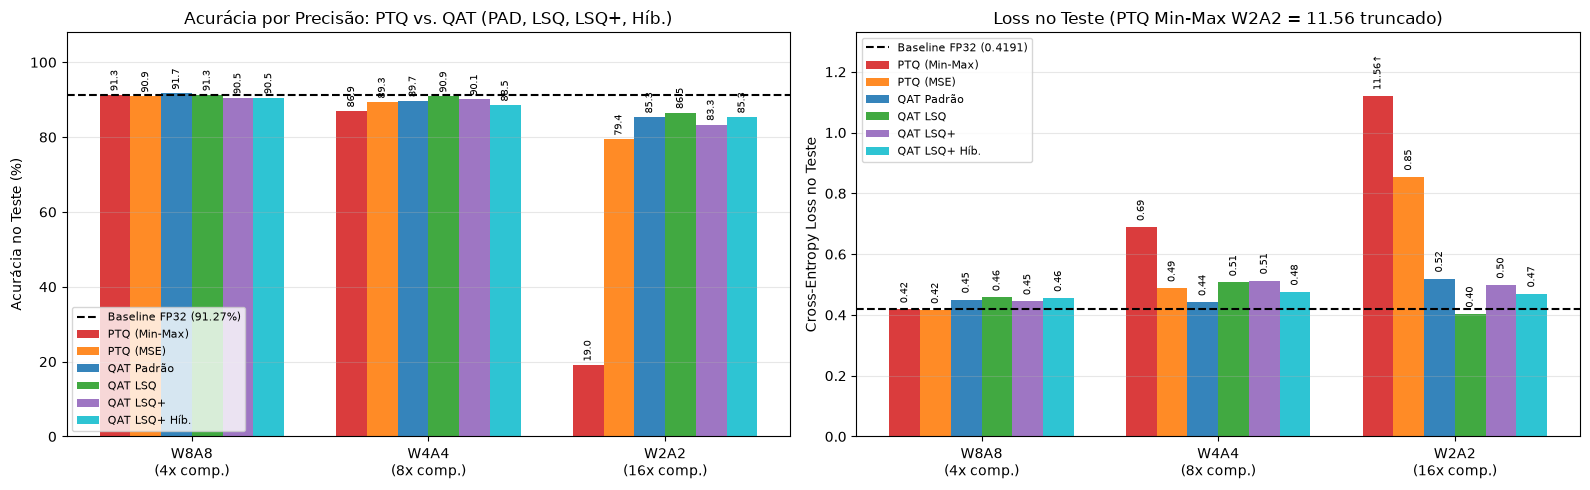

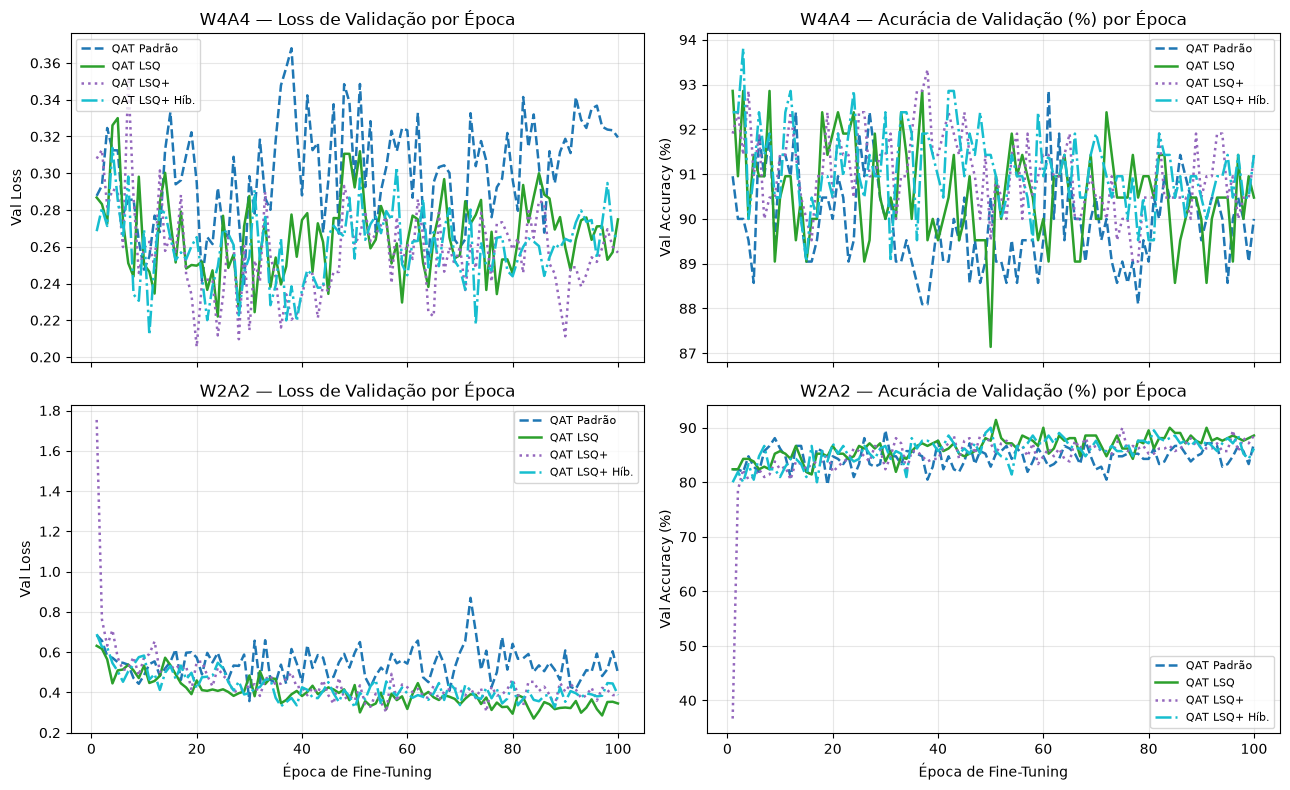


Modelo                   | Comp. |  Acc (%) |   Δ FP32 |  ΔPTQ-MSE |    Loss |    AUC |   F1-W
----------------------------------------------------------------------------------------------
Baseline FP32            |    1x |   91.27% |     0.00 |         — |  0.4191 | 0.9893 | 0.9131
----------------------------------------------------------------------------------------------
PTQ W8A8 (MINMAX)        |    4x |   91.27% | +0.00 pp |  +0.40 pp |  0.4183 | 0.9894 | 0.9128
PTQ W8A8 (MSE)           |    4x |   90.87% | -0.40 pp |   0.00 pp |  0.4162 | 0.9896 | 0.9090
QAT Padrão W8A8          |    4x |   91.67% | +0.40 pp |  +0.79 pp |  0.4507 | 0.9884 | 0.9173
QAT LSQ W8A8             |    4x |   91.27% | +0.00 pp |  +0.40 pp |  0.4580 | 0.9876 | 0.9130
QAT LSQ+ W8A8            |    4x |   90.48% | -0.79 pp |  -0.40 pp |  0.4450 | 0.9883 | 0.9048
QAT LSQ+ Híb W8A8        |    4x |   90.48% | -0.79 pp |  -0.40 pp |  0.4556 | 0.9885 | 0.9052
-------------------------------------------------

In [18]:
# 1. Figura 1: Comparação Global no Conjunto de Teste (252 amostras)
precisoes = [8, 4, 2]
labels_bits = ["W8A8\n(4x comp.)", "W4A4\n(8x comp.)", "W2A2\n(16x comp.)"]

metodos = [
    ("PTQ (Min-Max)",  lambda b: resultados_ptq[f"PTQ W{b}A{b} (MINMAX)"],          "#d62728"),
    ("PTQ (MSE)",      lambda b: resultados_ptq[f"PTQ W{b}A{b} (MSE)"],             "#ff7f0e"),
    ("QAT Padrão",     lambda b: resultados_qat_padrao[f"QAT Padrão W{b}A{b}"],     "#1f77b4"),
    ("QAT LSQ",        lambda b: resultados_lsq[f"QAT LSQ W{b}A{b}"],               "#2ca02c"),
    ("QAT LSQ+",       lambda b: resultados_lsq_plus[f"QAT LSQ+ W{b}A{b}"],         "#9467bd"),
    ("QAT LSQ+ Híb.",  lambda b: resultados_lsq_plus_hib[f"QAT LSQ+ Híb W{b}A{b}"], "#17becf"),
]

x = np.arange(len(precisoes))
largura = 0.13
offsets = (np.arange(len(metodos)) - (len(metodos) - 1) / 2) * largura

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Painel A: Acurácia (%)
ax = axes[0]
ax.axhline(metricas_fp32_test["acc"] * 100, color="black", linestyle="--",
           linewidth=1.5, label=f"Baseline FP32 ({metricas_fp32_test['acc']*100:.2f}%)")
for (nome, getter, cor), dx in zip(metodos, offsets):
    accs = [getter(b)["acc"] * 100 for b in precisoes]
    barras = ax.bar(x + dx, accs, width=largura, label=nome, color=cor, alpha=0.9)
    for bar, val in zip(barras, accs):
        ax.text(bar.get_x() + bar.get_width() / 2, val + 1.0, f"{val:.1f}",
                ha="center", va="bottom", fontsize=7.0, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(labels_bits)
ax.set_ylim(0, 108)
ax.set_ylabel("Acurácia no Teste (%)")
ax.set_title("Acurácia por Precisão: PTQ vs. QAT (PAD, LSQ, LSQ+, Híb.)")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="lower left")

# Painel B: Cross-Entropy Loss (recorte visual para não achatar pelo colapso de 11.56 no Min-Max W2A2)
ax = axes[1]
teto_loss = 1.15
ax.axhline(metricas_fp32_test["loss"], color="black", linestyle="--", linewidth=1.5,
           label=f"Baseline FP32 ({metricas_fp32_test['loss']:.4f})")
for (nome, getter, cor), dx in zip(metodos, offsets):
    losses = [getter(b)["loss"] for b in precisoes]
    losses_plot = [min(v, teto_loss - 0.03) for v in losses]
    barras = ax.bar(x + dx, losses_plot, width=largura, label=nome, color=cor, alpha=0.9)
    for bar, val, vp in zip(barras, losses, losses_plot):
        txt = f"{val:.2f}↑" if val > teto_loss else f"{val:.2f}"
        ax.text(bar.get_x() + bar.get_width() / 2, vp + 0.02, txt,
                ha="center", va="bottom", fontsize=7.0, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(labels_bits)
ax.set_ylim(0, teto_loss + 0.18)
ax.set_ylabel("Cross-Entropy Loss no Teste")
ax.set_title("Loss no Teste (PTQ Min-Max W2A2 = 11.56 truncado)")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()


# 2. Figura 2: Curvas de Convergência no QAT (W4A4 e W2A2) ao longo das 100 épocas
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
epocas_qat = range(1, len(historicos_lsq["QAT LSQ W2A2"]["val_loss"]) + 1)

curvas = [
    ("QAT Padrão",    historicos_qat_padrao,   "QAT Padrão",   "#1f77b4", "--"),
    ("QAT LSQ",       historicos_lsq,          "QAT LSQ",      "#2ca02c", "-"),
    ("QAT LSQ+",      historicos_lsq_plus,     "QAT LSQ+",     "#9467bd", ":"),
    ("QAT LSQ+ Híb.", historicos_lsq_plus_hib, "QAT LSQ+ Híb", "#17becf", "-."),
]

for linha, b in enumerate([4, 2]):
    for nome, hist_dict, prefixo, cor, ls in curvas:
        h = hist_dict[f"{prefixo} W{b}A{b}"]
        axes[linha, 0].plot(epocas_qat, h["val_loss"], label=nome, color=cor,
                            linestyle=ls, linewidth=1.8)
        axes[linha, 1].plot(epocas_qat, [a * 100 for a in h["val_acc"]], label=nome,
                            color=cor, linestyle=ls, linewidth=1.8)

    axes[linha, 0].set_title(f"W{b}A{b} — Loss de Validação por Época")
    axes[linha, 0].set_ylabel("Val Loss")
    axes[linha, 0].grid(True, alpha=0.3)
    axes[linha, 0].legend(fontsize=8)

    axes[linha, 1].set_title(f"W{b}A{b} — Acurácia de Validação (%) por Época")
    axes[linha, 1].set_ylabel("Val Accuracy (%)")
    axes[linha, 1].grid(True, alpha=0.3)
    axes[linha, 1].legend(fontsize=8)

axes[1, 0].set_xlabel("Época de Fine-Tuning")
axes[1, 1].set_xlabel("Época de Fine-Tuning")
plt.tight_layout()
plt.show()


# 3. Tabela Consolidada Final (com Taxa de Compressão dos Pesos e Ganho sobre PTQ MSE)
print("\n" + "=" * 94)
print(f"{'Modelo':<24} | {'Comp.':>5} | {'Acc (%)':>8} | {'Δ FP32':>8} | {'ΔPTQ-MSE':>9} | {'Loss':>7} | {'AUC':>6} | {'F1-W':>6}")
print("-" * 94)
acc_base = metricas_fp32_test["acc"] * 100
print(f"{'Baseline FP32':<24} | {'1x':>5} | {acc_base:7.2f}% | {'0.00':>8} | {'—':>9} | {metricas_fp32_test['loss']:7.4f} | {metricas_fp32_test['auc']:6.4f} | {metricas_fp32_test['f1_w']:6.4f}")
print("-" * 94)

for b in [8, 4, 2]:
    comp = f"{32 // b}x"
    acc_ptq_mse = resultados_ptq[f"PTQ W{b}A{b} (MSE)"]["acc"] * 100
    linhas = [
        (f"PTQ W{b}A{b} (MINMAX)",  resultados_ptq[f"PTQ W{b}A{b} (MINMAX)"]),
        (f"PTQ W{b}A{b} (MSE)",     resultados_ptq[f"PTQ W{b}A{b} (MSE)"]),
        (f"QAT Padrão W{b}A{b}",    resultados_qat_padrao[f"QAT Padrão W{b}A{b}"]),
        (f"QAT LSQ W{b}A{b}",       resultados_lsq[f"QAT LSQ W{b}A{b}"]),
        (f"QAT LSQ+ W{b}A{b}",      resultados_lsq_plus[f"QAT LSQ+ W{b}A{b}"]),
        (f"QAT LSQ+ Híb W{b}A{b}",  resultados_lsq_plus_hib[f"QAT LSQ+ Híb W{b}A{b}"]),
    ]
    for nome, m in linhas:
        acc_m = m["acc"] * 100
        d_fp32 = f"{acc_m - acc_base:+.2f} pp"
        d_ptq = f"{acc_m - acc_ptq_mse:+.2f} pp" if "MSE" not in nome else "0.00 pp"
        print(f"{nome:<24} | {comp:>5} | {acc_m:7.2f}% | {d_fp32:>8} | {d_ptq:>9} | {m['loss']:7.4f} | {m['auc']:6.4f} | {m['f1_w']:6.4f}")
    print("-" * 94)

## 5. Conclusão Final

### 5.1 Viabilidade de Compressão na Arquitetura KWS (`1.974` parâmetros)
- **Compressão `4x` (`W8A8`) — Resposta frente ao PTQ do Edge Impulse:** Praticamente sem perdas (em linha com Carlos, 2025; Ravaglia et al., 2021). Como o `PTQ` em 8 bits já preserva o modelo (`91.27%` no `Min-Max`), o ganho do `QAT` nesse regime é apenas marginal (`91.67%` no `QAT Padrão`, `+0.40 p.p.`), confirmando que em `INT8` o `PTQ` já é suficiente. Tanto `PTQ Min-Max` (`91.27%`) quanto `QAT LSQ` (`91.27%`) igualam o **Baseline FP32 (`91.27%`)**, e o `QAT Padrão` atinge `91.67%`. Em 8 bits, o erro de projeção $\Delta W$ é pequeno o suficiente para manter o termo quadrático de segunda ordem $\frac{1}{2}\Delta W^T \mathbf{H} \Delta W \approx 0$ (Antoniou & Lu, 2007; Souza, 2026).
- **Compressão `8x` (`W4A4`) — Ponto Ótimo de Operação:** A quantização pós-treino ingênua (`PTQ Min-Max`) perde `-4.37 p.p.` (`86.90%`), reduzida para `-1.98 p.p.` com calibração `PTQ MSE` (`89.29%`). O **QAT LSQ** recupera quase toda a degradação e alcança **`90.87%` (`-0.40 p.p.` vs. FP32)**, perdendo apenas 1 amostra adicional em 252.
- **Compressão `16x` (`W2A2`) — Limite Extremo:** Com apenas 4 níveis por tensor, `PTQ Min-Max` colapsa (`19.05%`, Loss `11.5572`). O `PTQ MSE` evita o colapso (`79.37%`), mas o **QAT LSQ** entrega o melhor desempenho global com **`86.51%`** (`+7.14 p.p.` sobre `PTQ MSE` e `+1.19 p.p.` sobre `QAT Padrão`), além de obter a menor *Cross-Entropy Loss* no teste (**`0.4037`**, inferior inclusive ao Baseline FP32 de `0.4191`).

### 5.2 Por que o QAT LSQ superou o QAT Padrão e as variantes LSQ+?
1. **LSQ vs. QAT Padrão (Precondicionamento e Co-otimização de $s$):** No QAT Padrão, o passo $s$ permanece fixo na inicialização estática (MSE pré-treino), forçando todos os ajustes da rede a ocorrerem apenas nos pesos via STE — o que gera instabilidades em `W2A2` (como o pico tardio de `Val Loss ~0.88` na época 72). No **LSQ** (Bhalgat et al., 2020), o passo $s$ é otimizado em conjunto com os pesos e escalonado pelo fator $g = 1/\sqrt{N \cdot Q_p}$ (`grad_scale`), funcionando como um precondicionamento diagonal para mitigar o mau condicionamento entre os gradientes de $s$ e de $W$ (Antoniou & Lu, 2007; Souza, 2026), resultando na curva de convergência mais suave e de menor variância.
2. **LSQ vs. LSQ+ (Geometria da Fronteira da `ReLU` e *Zero-Point Drift*):** A manutenção fiel da ativação **`ReLU`** do TCC original (Carlos, 2025) ($\max(0, x)$, onde $v = 0$ concentra grande massa de probabilidade após o corte dos valores negativos) cria uma restrição geométrica natural: o nível quantizado $q = 0$ precisa representar exatamente `0.0`. Ao inicializar `LSQ+` com *offset* $\beta$ irrestrito via MSE nas ativações pós-`ReLU` (`a1` com $\beta_{\text{init}} = +0.1867$ e `a2` com $+0.2149$ em `W2A2`), todos os neurônios zerados passaram a receber um viés positivo espúrio, causando o pico inicial de `Val Loss ~1.75` (`Val Acc ~37%`) na Época 1.
3. **Ablação via `LSQ+ Híbrido` (Projeção $\beta = 0$ pós-ReLU):** Ao projetar a restrição $\beta = 0$ em `a1` e `a2` e manter $\beta$ livre apenas na entrada MFCC (`in`), a acurácia em `W2A2` recuperou **`+1.99 p.p.` sobre o `LSQ+` padrão** (`83.33%` $\rightarrow$ `85.32%`, com `Loss` caindo de `0.4992` para `0.4703` e `ruido` saltando de `69.8%` para `81.4%`), comprovando causalmente o efeito do *Zero-Point Drift* nas camadas `ReLU`. Ainda assim, o **`LSQ` puro (`86.51%`, Loss `0.4037`)** permaneceu superior porque a entrada MFCC normalizada por CMVN possui média centrada em zero, beneficiando-se de uma grade simétrica que preserva o nível exato `0.0` em 2 bits.

### 5.3 Trabalhos Futuros
- Investigar funções de ativação limitadas ou com cauda negativa suave (**Bounded ReLU** — Zhao et al., 2021 — ou **Swish/SiLU**), cenário em que Bhalgat et al. (2020) demonstram ganhos consistentes para o `LSQ+` em 2 bits.
- Avaliar quantização de **precisão mista (*mixed precision*)** entre camadas (`conv1`, `conv2` e `fc`) guiada pela sensibilidade de segunda ordem (curvatura/Hessiana; Antoniou & Lu, 2007; Souza, 2026) e validar o modelo `W4A4`/`W2A2` compilado em aritmética inteira pura no microcontrolador alvo.

## 6. Referências

- **[Antoniou & Lu, 2007]** A. Antoniou and W.-S. Lu, *Practical Optimization: Algorithms and Engineering Applications*. New York, NY, USA: Springer Science+Business Media, 2007, ISBN: `978-0-387-71106-5`.
- **[Bhalgat et al., 2020]** Y. Bhalgat, J. Lee, M. Nagel, T. Blankevoort, and N. Kwak, *"LSQ+: Improving low-bit quantization through learnable offsets and better initialization,"* in *Proc. IEEE/CVF Conference on Computer Vision and Pattern Recognition Workshops (CVPRW)*, 2020.
- **[Carlos, 2025]** P. H. P. da S. Carlos, *"Sistema Embarcado para Reconhecimento de Palavras usando ESP32-S3 e TinyML,"* Trabalho de Conclusão de Curso (Engenharia de Computação), Escola Politécnica, Universidade Federal da Bahia (UFBA), Salvador, BA, Brasil, maio 2025.
- **[Lin et al., 2023]** S.-T. Lin, Z. Li, Y.-H. Cheng, H.-W. Kuo, R.-H. Wang, N.-J. Sung, C.-C. Lu, and K.-T. Tang, *"LG-LSQ: Learned Gradient Linear Symmetric Quantization for Low-Precision Integer Hardware,"* in *Proc. IEEE 5th International Conference on Artificial Intelligence Circuits and Systems (AICAS)*, 2023, doi: `10.1109/AICAS57966.2023.10168649`.
- **[Pereira et al., 2023]** P. H. Pereira, W. Beccaro, and M. A. Ramírez, *"Evaluating Robustness to Noise and Compression of Deep Neural Networks for Keyword Spotting,"* *IEEE Access*, vol. 11, 2023, doi: `10.1109/ACCESS.2023.3280477`.
- **[Ravaglia et al., 2021]** L. Ravaglia, M. Rusci, D. Nadalini, A. Capotondi, F. Conti, and L. Benini, *"A TinyML Platform for On-Device Continual Learning With Quantized Latent Replays,"* *IEEE Journal on Emerging and Selected Topics in Circuits and Systems (JETCAS)*, vol. 11, no. 4, Dec. 2021.
- **[Souza, 2026]** E. E. P. de Souza, *Notas de Aula — Otimização (PPGEE0016)*. Programa de Pós-Graduação em Engenharia Elétrica e Computação, Universidade Federal da Bahia (UFBA), 2026.
- **[Zhao et al., 2021]** H. Zhao, D. Liu, and H. Li, *"Efficient Integer-Arithmetic-Only Convolutional Networks With Bounded ReLU,"* in *Proc. IEEE International Symposium on Circuits and Systems (ISCAS)*, 2021, doi: `10.1109/ISCAS51556.2021.9401448`.